# 🎹 DeepMidi-LSTM: Generación Musical con Redes Neuronales Recurrentes (LSTM)
- **Carrera:** Inteligencia Artificial y Aprendizaje Automático
- **Materia:** Diseño, Visualización y Comprension de Deep Neural Networks
- **Alumno:** Roberto Alejandro Chagra Martinez
- **Código:** 208447128

---
## Tabla de contenidos del notebook
- **Parte 0.** Preparación del entorno de ejecución y resolución de rutas en Google Drive.
- **Parte 1.** Adquisición y selección representativa del dataset (`examples/`).
- **Parte 2.** Exploración simbólica y acústica con `symusic` e instrumentación General MIDI.
- **Parte 3.** Limpieza algorítmica, selección de pista principal y criterios de descarte.
- **Parte 4.** Tokenización estructurada con REMI de MidiTok y construcción del vocabulario.
- **Parte 5.** Análisis estadístico de secuencias de tokens y filtrado de densidad.
- **Parte 6.** Construcción del dataset autorregresivo, división estratificada y DataLoaders.
- **Parte 7.** Arquitectura y entrenamiento de la red LSTM con validación y early stopping.
- **Parte 8.** Generación musical autorregresiva con control de temperatura y muestreo Top-K.
- **Parte 9.** Evaluación métrica comparativa de la composición frente al conjunto real.
- **Parte 10.** Síntesis acústica mediante osciladores armónicos y envolvente ADSR (exportación WAV).
- **Parte 11.** Visualización: Piano roll estático y partituras interactivas animadas
- **Parte 12.** Resumen ejecutivo de resultados y exportación final.

## Parte 0.  Preparación del entorno de ejecución y resolución de rutas en Google Drive.

*   Instalación de dependencias no preinstaladas en el entorno  
*   Importación de librerías para el pipeline completo
*   Configuración para reproducción de audio y renderizado HTML en entornos interactivos  
*   Configuración de semilla para reproducibilidad experimental  
*   Detección de entorno: montaje de Google Drive en Colab o uso de rutas locales
*   Resolución dinámica de rutas  
*   Constantes globales del pipeline


In [ ]:
# @title Preparación del entorno de ejecución y definición de rutas

# Instalación de dependencias no preinstaladas en el entorno
!pip install -q miditok symusic pretty_midi seaborn gdown

# Importación de librerías para el pipeline completo
import json
import math
import os
import random
import wave
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import symusic
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from miditok import REMI, TokenizerConfig
from torch.utils.data import DataLoader, Dataset

# Configuración para reproducción de audio y renderizado HTML en entornos interactivos
try:
    from IPython.display import Audio, HTML, display
except ImportError:
    class Audio:
        def __init__(self, filename=None, *args, **kwargs):
            self.filename = filename
        def __repr__(self):
            return f"<Audio: {self.filename}>"
    class HTML:
        def __init__(self, data):
            self.data = data
        def __repr__(self):
            return self.data
    display = print

# Configuración de semilla para reproducibilidad experimental
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Detección de entorno: montaje de Google Drive en Colab o uso de rutas locales
EN_COLAB = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    EN_COLAB = True
    print("[DRIVE] Google Drive montado exitosamente en /content/drive.")
except ImportError:
    print("[DRIVE] Ejecución en entorno local / Google Drive para escritorio.")

# Enlace público a la carpeta general 'examples/' en Google Drive para evaluadores/terceros:
URL_PUBLIC_EXAMPLES = "https://drive.google.com/drive/folders/1-zbR2yBDIdOSCg3YAAyU5ye35SOLRlI3"

# Resolución dinámica de rutas:
# Detección automática en Google Colab (MyDrive o Shareddrives) o entorno local (Windows / relativo).
posibles_raices = [
    Path("G:/Mi unidad/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("G:/Shared drives/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("/content/drive/Shareddrives/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("/content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("/content/drive/MyDrive/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("/content/drive/MyDrive/DeepMidi_LSTM_Generacion_Musical"),
    Path("G:/Mi unidad/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI"),
    Path("G:/Shared drives/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI"),
    Path("/content/drive/Shareddrives/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI"),
    Path("/content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI"),
    Path("/content/drive/MyDrive/Proyectos/Proyecto_MIDI"),
    Path("/content/drive/MyDrive/Proyecto_MIDI"),
    Path("/content/drive/MyDrive"),
    Path.cwd(),
    Path("."),
]

DRIVE_PROYECTO = None
for ruta in posibles_raices:
    if (ruta / "examples").exists():
        DRIVE_PROYECTO = ruta
        break

# Si no se encuentra localmente ni en el Drive montado (ejecución por un tercero en Colab):
if DRIVE_PROYECTO is None or not (DRIVE_PROYECTO / "examples").exists():
    print("[DATASET] No se detectó 'examples/' en el Drive montado ni en rutas locales.")
    print("[DATASET] Descargando corpus 'examples/' automáticamente desde la carpeta pública de Google Drive...")
    import gdown
    try:
        gdown.download_folder(URL_PUBLIC_EXAMPLES, output="examples", quiet=False, use_cookies=False)
    except Exception as e:
        print(f"[DATASET] Aviso en gdown API ({e}). Ejecutando comando shell...")
        os.system(f'gdown --folder "{URL_PUBLIC_EXAMPLES}" -O examples')
    DRIVE_PROYECTO = Path.cwd()
    print(f"[OK] Dataset descargado exitosamente en: {DRIVE_PROYECTO / 'examples'}")

EXAMPLES_DIR = DRIVE_PROYECTO / "examples"
RAW_DIR = EXAMPLES_DIR
CLEAN_DIR = DRIVE_PROYECTO / "dataset_midi_clean"
RESULTS_DIR = DRIVE_PROYECTO / "results"

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Constantes globales del pipeline
MIN_PITCH, MAX_PITCH = 21, 108       # Registro de piano de 88 teclas (A0 a C8)
MIN_NOTES_THRESHOLD = 50             # Mínimo de 50 notas en la pista seleccionada
MIN_DURATION_SECONDS = 5.0           # Duración mínima de 5 segundos
MAX_OUT_OF_RANGE_PCT = 5.0           # Tolerancia máxima del 5% de notas fuera de rango
TARGET_PROGRAMS = set(range(0, 8))   # Programas de piano acústico y eléctrico (GM 0-7)
MIN_TOKENS_USABLE = 64               # Umbral mínimo de tokens para considerarse utilizable
MAX_LEN = 256                        # Longitud de ventana de contexto (L=256, solapamiento 50%)
SPLIT_TRAIN = 0.8                    # División: 80% entrenamiento, 20% validación
BATCH_SIZE = 32                      # Tamaño de lote óptimo para la red LSTM

# Detección y asignación de acelerador (GPU / CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[DISPOSITIVO] Dispositivo seleccionado para entrenamiento: {device}")
print(f"[RUTAS] Directorio base del proyecto: {DRIVE_PROYECTO}")
print(f"[RUTAS] Directorio del dataset (RAW_DIR): {RAW_DIR}")
print(f"[RUTAS] Directorio de datos limpios (CLEAN_DIR): {CLEAN_DIR}")
print(f"[RUTAS] Directorio de resultados (RESULTS_DIR): {RESULTS_DIR}")
print("[OK] Entorno y directorios configurados correctamente.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DRIVE] Google Drive montado exitosamente en /content/drive.
[DISPOSITIVO] Dispositivo seleccionado para entrenamiento: cuda
[RUTAS] Directorio base del proyecto: /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical
[RUTAS] Directorio del dataset (RAW_DIR): /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/examples
[RUTAS] Directorio de datos limpios (CLEAN_DIR): /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/dataset_midi_clean
[RUTAS] Directorio de resultados (RESULTS_DIR): /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/results
[OK] Entorno y directorios configurados correctamente.


## Parte 1. Adquisición y selección del dataset

Exploración y carga estructurada del corpus MIDI almacenado en Google Drive (`examples/`), organizado jerárquicamente por género musical y artista (`[Género]/[Artista]/[canción.mid]`). Para asegurar la reproducibilidad y balance del entrenamiento, se realiza un muestreo determinístico de `MAX_CANCIONES` mediante una semilla fija (`SEED = 42`), garantizando una representación variada y balanceada de los distintos géneros y estilos musicales.


In [ ]:
# @title Adquisición y selección del dataset

# Definición del número máximo de canciones a seleccionar
MAX_CANCIONES = 20

# Búsqueda recursiva de archivos MIDI en RAW_DIR (examples/).
if not RAW_DIR.exists():
    raise RuntimeError(
        f"No se encontró el directorio de archivos MIDI en '{RAW_DIR}'. "
        "Verifique la conexión con Google Drive y la presencia de la carpeta 'examples'."
    )

# Escaneo optimizado de directorios mediante os.walk:
todos_midi = sorted([
    Path(root) / f
    for root, _, filenames in os.walk(RAW_DIR)
    for f in filenames
    if f.lower().endswith((".mid", ".midi"))
])
print(f"Total de archivos MIDI encontrados en '{RAW_DIR}': {len(todos_midi)}")
if len(todos_midi) == 0:
    raise RuntimeError(
        "No se encontraron archivos .mid en la ruta especificada. "
        "Verifique que la carpeta 'examples' contenga archivos MIDI organizados."
    )

# Selección determinística de una muestra de MAX_CANCIONES canciones:
orden = list(range(len(todos_midi)))
random.seed(SEED)
random.shuffle(orden)
seleccion_idx = orden[:MAX_CANCIONES]
midi_files = [todos_midi[i] for i in seleccion_idx]

# Análisis de la estructura jerárquica: partes[0] = Género Musical, partes[1] = Artista
conteo_generos = Counter()
conteo_artistas = Counter()
for p in midi_files:
    parts = p.relative_to(RAW_DIR).parts
    genero = parts[0] if len(parts) > 1 else "General"
    artista = parts[1] if len(parts) > 2 else (parts[0] if len(parts) == 2 else "Varios")
    conteo_generos[genero] += 1
    conteo_artistas[artista] += 1

print(f"\nSelección de muestra: {len(midi_files)} canciones.")
print(f"Distribución por Género Musical ({len(conteo_generos)} géneros representados):")
for gen, n in conteo_generos.most_common():
    print(f"  - {gen}: {n} canciones")

print(f"\nTop 10 artistas representados (de {len(conteo_artistas)} artistas en la muestra):")
for art, n in conteo_artistas.most_common(10):
    print(f"  - {art}: {n} canciones")
if len(conteo_artistas) > 10:
    print(f"  ... y {len(conteo_artistas) - 10} artistas más.")

Total de archivos MIDI encontrados en '/content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI/examples/Pop/Michael Jackson': 21

Selección de muestra: 20 canciones.
Distribución por Género Musical (1 géneros representados):
  - General: 20 canciones

Top 10 artistas representados (de 1 artistas en la muestra):
  - Varios: 20 canciones


## Parte 2. Exploración de archivos MIDI

Auditoría simbólica y acústica de cada archivo mediante `symusic`: duración temporal, conteo total de notas, densidad polifónica, presencia de percusión y rango tonal. Se examina la presencia de pistas múltiples y la proporción de notas comprendidas dentro del registro estándar de piano de 88 teclas ($A_0$ a $C_8$, notas MIDI 21 a 108).


In [ ]:
# @title Exploración de archivos MIDI

# Mapeo estándar General MIDI para identificación de instrumentos
GM_PROGRAMS = {
    0: "Acoustic Grand Piano", 1: "Bright Acoustic Piano", 2: "Electric Grand Piano",
    3: "Honky-tonk Piano", 4: "Electric Piano 1", 5: "Electric Piano 2",
    6: "Harpsichord", 7: "Clavi", 8: "Celesta", 9: "Glockenspiel",
    10: "Music Box", 11: "Vibraphone", 12: "Marimba", 13: "Xylophone",
    14: "Tubular Bells", 15: "Dulcimer", 16: "Drawbar Organ", 17: "Percussive Organ",
    18: "Rock Organ", 19: "Church Organ", 20: "Reed Organ", 21: "Accordion",
    22: "Harmonica", 23: "Tango Accordion", 24: "Acoustic Guitar (nylon)",
    25: "Acoustic Guitar (steel)", 26: "Electric Guitar (jazz)", 27: "Electric Guitar (clean)",
    28: "Electric Guitar (muted)", 29: "Overdriven Guitar", 30: "Distortion Guitar",
    31: "Guitar harmonics", 32: "Acoustic Bass", 33: "Electric Bass (finger)",
    34: "Electric Bass (pick)", 35: "Fretless Bass", 36: "Slap Bass 1",
    37: "Slap Bass 2", 38: "Synth Bass 1", 39: "Synth Bass 2", 40: "Violin",
    41: "Viola", 42: "Cello", 43: "Contrabass", 44: "Tremolo Strings",
    45: "Pizzicato Strings", 46: "Orchestral Harp", 47: "Timpani",
    48: "String Ensemble 1", 49: "String Ensemble 2", 50: "SynthStrings 1",
    51: "SynthStrings 2", 52: "Choir Aahs", 53: "Voice Oohs", 54: "Synth Voice",
    55: "Orchestra Hit", 56: "Trumpet", 57: "Trombone", 58: "Tuba",
    59: "Muted Trumpet", 60: "French Horn", 61: "Brass Section",
    62: "SynthBrass 1", 63: "SynthBrass 2", 64: "Soprano Sax", 65: "Alto Sax",
    66: "Tenor Sax", 67: "Baritone Sax", 68: "Oboe", 69: "English Horn",
    70: "Bassoon", 71: "Clarinet", 72: "Piccolo", 73: "Flute", 74: "Recorder",
    75: "Pan Flute", 76: "Blown Bottle", 77: "Shakuhachi", 78: "Whistle",
    79: "Ocarina", 80: "Lead 1 (square)", 81: "Lead 2 (sawtooth)",
    82: "Lead 3 (calliope)", 83: "Lead 4 (chiff)", 84: "Lead 5 (charang)",
    85: "Lead 6 (voice)", 86: "Lead 7 (fifths)", 87: "Lead 8 (bass + lead)",
    88: "Pad 1 (new age)", 89: "Pad 2 (warm)", 90: "Pad 3 (polysynth)",
    91: "Pad 4 (choir)", 92: "Pad 5 (bowed)", 93: "Pad 6 (metallic)",
    94: "Pad 7 (halo)", 95: "Pad 8 (sweep)", 96: "FX 1 (rain)",
    97: "FX 2 (soundtrack)", 98: "FX 3 (crystal)", 99: "FX 4 (atmosphere)",
    100: "FX 5 (brightness)", 101: "FX 6 (goblins)", 102: "FX 7 (echoes)",
    103: "FX 8 (sci-fi)", 104: "Sitar", 105: "Banjo", 106: "Shamisen",
    107: "Koto", 108: "Kalimba", 109: "Bag pipe", 110: "Fiddle", 111: "Shanai",
    112: "Tinkle Bell", 113: "Agogo", 114: "Steel Drums", 115: "Woodblock",
    116: "Taiko Drum", 117: "Melodic Tom", 118: "Synth Drum",
    119: "Reverse Cymbal", 120: "Guitar Fret Noise", 121: "Breath Noise",
    122: "Seashore", 123: "Bird Tweet", 124: "Telephone Ring", 125: "Helicopter",
    126: "Applause", 127: "Gunshot",
}


def gm_name(program):
    '''Retorna el nombre estándar General MIDI asociado a un número de programa.'''
    return GM_PROGRAMS.get(program, f"Programa GM {program}")


def inspeccionar_midi(file_path):
    '''Extrae duración, métricas de notas, instrumentación y rango tonal de un archivo MIDI.'''
    try:
        score = symusic.Score.from_file(str(file_path))
        duration_sec = float(score.to("second").end())
        total_notes = int(score.note_num())
        has_drums = bool(any(t.is_drum for t in score.tracks))
        programs = sorted({t.program for t in score.tracks if not t.is_drum})
        all_pitches = [n.pitch for t in score.tracks for n in t.notes]
        if all_pitches:
            min_pitch = int(min(all_pitches))
            max_pitch = int(max(all_pitches))
            in_range = sum(MIN_PITCH <= p <= MAX_PITCH for p in all_pitches)
            pct_in_range = 100.0 * in_range / len(all_pitches)
        else:
            min_pitch, max_pitch, pct_in_range = None, None, 0.0
        return {
            "status": "OK", "error_msg": "",
            "duration_sec": round(duration_sec, 2),
            "total_notes": total_notes,
            "num_tracks": len(score.tracks),
            "is_multi_track": len(score.tracks) > 1,
            "has_drums": has_drums,
            "programs": programs,
            "program_names": [gm_name(p) for p in programs],
            "min_pitch": min_pitch, "max_pitch": max_pitch,
            "pct_in_range_21_108": round(pct_in_range, 2),
        }
    except Exception as e:
        return {
            "status": "ERROR", "error_msg": str(e),
            "duration_sec": None, "total_notes": 0, "num_tracks": 0,
            "is_multi_track": False, "has_drums": False,
            "programs": [], "program_names": [],
            "min_pitch": None, "max_pitch": None, "pct_in_range_21_108": 0.0,
        }


exploration_rows = []
for file in midi_files:
    parts = file.relative_to(RAW_DIR).parts
    genero = parts[0] if len(parts) > 1 else "General"
    artista = parts[1] if len(parts) > 2 else (parts[0] if len(parts) == 2 else "Varios")
    record = {
        "file_path": str(file),
        "rel_path": str(file.relative_to(RAW_DIR)),
        "grupo": genero,
        "genero": genero,
        "artista": artista,
        "filename": file.name,
    }
    record.update(inspeccionar_midi(file))
    exploration_rows.append(record)
    if record["status"] == "OK":
        print(
            f"[{record['filename']}] {record['duration_sec']:.1f}s | "
            f"{record['total_notes']} notas | pistas={record['num_tracks']} | "
            f"percusión={record['has_drums']} | "
            f"instrumentos={record['program_names']} | "
            f"rango={record['min_pitch']}-{record['max_pitch']} | "
            f"en rango 21-108: {record['pct_in_range_21_108']:.1f}%"
        )
    else:
        print(f"[{record['filename']}] Error de lectura: {record['error_msg']}")

df_exploration = pd.DataFrame(exploration_rows)
print(f"\nArchivos explorados: {len(df_exploration)} | Lecturas correctas: {(df_exploration['status'] == 'OK').sum()}")
display(df_exploration[["filename", "genero", "artista", "status", "duration_sec", "total_notes",
                        "num_tracks", "has_drums", "min_pitch", "max_pitch",
                        "pct_in_range_21_108"]].head(20))


[Thriller.mid] 335.9s | 8965 notas | pistas=11 | percusión=True | instrumentos=['Electric Piano 2', 'Church Organ', 'Electric Guitar (muted)', 'Fretless Bass', 'String Ensemble 1', 'Synth Voice', 'Brass Section', 'Tenor Sax', 'Pan Flute', 'Agogo'] | rango=26-96 | en rango 21-108: 100.0%
[Human Nature.mid] 268.8s | 3843 notas | pistas=8 | percusión=True | instrumentos=['Fretless Bass', 'Brass Section', 'Soprano Sax', 'Oboe', 'Pad 3 (polysynth)'] | rango=32-92 | en rango 21-108: 100.0%
[She's Out Of My Life.mid] 231.1s | 1502 notas | pistas=6 | percusión=True | instrumentos=['Electric Piano 1', 'Acoustic Guitar (steel)', 'Fretless Bass', 'String Ensemble 2', 'English Horn'] | rango=28-85 | en rango 21-108: 100.0%
[Heal The World.mid] 339.0s | 9124 notas | pistas=11 | percusión=True | instrumentos=['Acoustic Grand Piano', 'Bright Acoustic Piano', 'Acoustic Guitar (steel)', 'Fretless Bass', 'String Ensemble 1', 'String Ensemble 2', 'Choir Aahs', 'Alto Sax', 'Flute', 'Pad 2 (warm)'] | rango

,filename,genero,artista,status,duration_sec,total_notes,num_tracks,has_drums,min_pitch,max_pitch,pct_in_range_21_108
0,Thriller.mid,General,Varios,OK,335.90,8965,11,True,26,96,100.00
1,Human Nature.mid,General,Varios,OK,268.78,3843,8,True,32,92,100.00
2,She's Out Of My Life.mid,General,Varios,OK,231.07,1502,6,True,28,85,100.00
3,Heal The World.mid,General,Varios,OK,338.99,9124,11,True,29,93,100.00
4,Liberian Girl.mid,General,Varios,OK,220.66,3414,11,True,24,86,100.00
5,Rock With You.mid,General,Varios,OK,270.78,5145,13,True,26,95,100.00
6,Smooth Criminal.mid,General,Varios,OK,208.97,5424,11,True,27,96,100.00
7,The Way You Make Me Feel.mid,General,Varios,OK,414.00,10192,12,True,29,96,100.00
8,I Just Can't Stop Loving You.mid,General,Varios,OK,231.33,4904,11,True,23,102,100.00
9,Remember the Time.mid,General,Varios,OK,171.18,1556,7,True,48,79,100.00


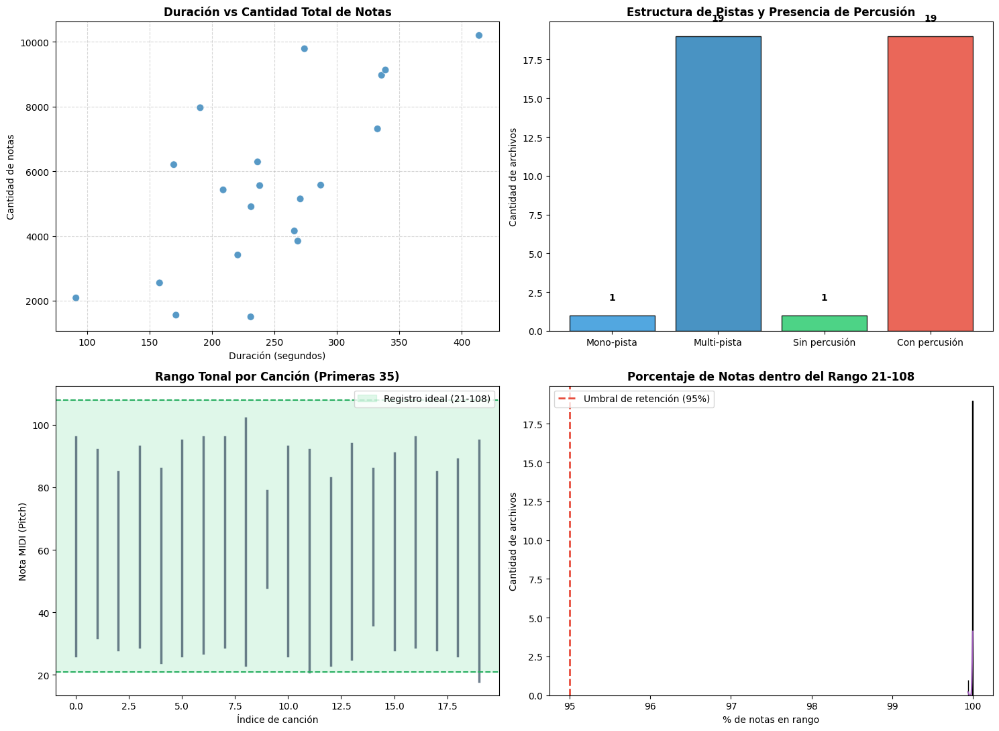

Gráficas de exploración guardadas en 'parte2_exploracion.png' dentro de results/.


In [ ]:
# @title Visualización de métricas acústicas y estructurales

valid_exploration = df_exploration[df_exploration["status"] == "OK"].copy()

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Gráfica 1: Duración vs Cantidad de notas
ax1 = axes[0, 0]
sns.scatterplot(
    data=valid_exploration, x="duration_sec", y="total_notes",
    hue="grupo", alpha=0.75, s=60, ax=ax1, legend=False
)
ax1.set_title("Duración vs Cantidad Total de Notas", fontsize=12, fontweight="bold")
ax1.set_xlabel("Duración (segundos)")
ax1.set_ylabel("Cantidad de notas")
ax1.grid(True, linestyle="--", alpha=0.5)

# Gráfica 2: Proporción de archivos multipista y percusión
ax2 = axes[0, 1]
conteos = {
    "Mono-pista": (~valid_exploration["is_multi_track"]).sum(),
    "Multi-pista": valid_exploration["is_multi_track"].sum(),
    "Sin percusión": (~valid_exploration["has_drums"]).sum(),
    "Con percusión": valid_exploration["has_drums"].sum(),
}
colores = ["#3498db", "#2980b9", "#2ecc71", "#e74c3c"]
ax2.bar(conteos.keys(), conteos.values(), color=colores, edgecolor="black", alpha=0.85)
ax2.set_title("Estructura de Pistas y Presencia de Percusión", fontsize=12, fontweight="bold")
ax2.set_ylabel("Cantidad de archivos")
for i, (k, v) in enumerate(conteos.items()):
    ax2.text(i, v + 1, str(v), ha="center", fontweight="bold")

# Gráfica 3: Distribución de rangos de pitch frente al registro estándar de piano
ax3 = axes[1, 0]
for idx, (_, row) in enumerate(valid_exploration.head(35).iterrows()):
    p_min = row["min_pitch"]
    p_max = row["max_pitch"]
    if p_min is not None and p_max is not None:
        ax3.plot([idx, idx], [p_min, p_max], color="#34495e", linewidth=2.5, alpha=0.7)
ax3.axhspan(MIN_PITCH, MAX_PITCH, color="#2ecc71", alpha=0.15, label=f"Registro ideal ({MIN_PITCH}-{MAX_PITCH})")
ax3.axhline(MIN_PITCH, color="#27ae60", linestyle="--", linewidth=1.5)
ax3.axhline(MAX_PITCH, color="#27ae60", linestyle="--", linewidth=1.5)
ax3.set_title("Rango Tonal por Canción (Primeras 35)", fontsize=12, fontweight="bold")
ax3.set_xlabel("Índice de canción")
ax3.set_ylabel("Nota MIDI (Pitch)")
ax3.legend(loc="upper right")

# Gráfica 4: Histograma del porcentaje de notas en rango de piano
ax4 = axes[1, 1]
sns.histplot(
    valid_exploration["pct_in_range_21_108"], bins=15, kde=True,
    color="#9b59b6", ax=ax4, edgecolor="black"
)
ax4.axvline(100.0 - MAX_OUT_OF_RANGE_PCT, color="#e74c3c", linestyle="--", linewidth=2,
            label=f"Umbral de retención ({100.0 - MAX_OUT_OF_RANGE_PCT:.0f}%)")
ax4.set_title("Porcentaje de Notas dentro del Rango 21-108", fontsize=12, fontweight="bold")
ax4.set_xlabel("% de notas en rango")
ax4.set_ylabel("Cantidad de archivos")
ax4.legend(loc="upper left")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte2_exploracion.png", dpi=150)
plt.show()
print("Gráficas de exploración guardadas en 'parte2_exploracion.png' dentro de results/.")


## Parte 3. Limpieza y preparación

Filtrado algorítmico y aislamiento de la pista melódica/armónica principal por canción bajo criterios formales de calidad:
1. **Eliminación de percusión:** Se descartan las pistas con indicador `is_drum = True`.
2. **Priorización de instrumentación:** Se prefieren pistas con timbres de piano acústico/eléctrico (General MIDI 0 a 7). Si no se detectan, se selecciona la pista instrumental con mayor densidad de notas.
3. **Umbrales mínimos de calidad:** Se descartan pistas con menos de 50 notas, duración inferior a 5 segundos o con más del 5% de notas fuera del registro de piano de 88 teclas.
4. **Almacenamiento limpio:** Cada pista seleccionada se exporta como un archivo MIDI limpio de una sola pista a `CLEAN_DIR`.


In [ ]:
# @title Limpieza y preparación

cleaning_records = []
kept_files = []

for row in exploration_rows:
    filename = row["filename"]
    file_path = row["file_path"]
    if row["status"] != "OK":
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": f"Archivo corrupto o ilegible ({row['error_msg']})",
            "selected_track_name": None, "selected_program": None,
            "selected_notes": 0, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: archivo corrupto o ilegible.")
        continue
    score = symusic.Score.from_file(file_path)
    candidate_tracks = [t for t in score.tracks if not t.is_drum]
    if not candidate_tracks:
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": "Solo contiene pistas de percusión (drums)",
            "selected_track_name": None, "selected_program": None,
            "selected_notes": 0, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: solo contiene pistas de percusión.")
        continue
    # Priorización de pistas de piano (GM 0-7) o selección por máxima densidad de notas
    piano_tracks = [t for t in candidate_tracks if t.program in TARGET_PROGRAMS]
    pool = piano_tracks if piano_tracks else candidate_tracks
    selected_track = max(pool, key=lambda t: len(t.notes))
    track_notes_count = len(selected_track.notes)
    if track_notes_count < MIN_NOTES_THRESHOLD:
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": f"Cantidad de notas insuficiente ({track_notes_count} < {MIN_NOTES_THRESHOLD})",
            "selected_track_name": selected_track.name or "Track",
            "selected_program": int(selected_track.program),
            "selected_notes": track_notes_count, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: notas insuficientes ({track_notes_count} < {MIN_NOTES_THRESHOLD}).")
        continue
    duration = float(score.to("second").end())
    if duration < MIN_DURATION_SECONDS:
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": f"Duración muy corta ({duration:.1f}s < {MIN_DURATION_SECONDS}s)",
            "selected_track_name": selected_track.name or "Track",
            "selected_program": int(selected_track.program),
            "selected_notes": track_notes_count, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: duración muy corta ({duration:.1f}s < {MIN_DURATION_SECONDS}s).")
        continue
    pct_out = 100.0 - row["pct_in_range_21_108"]
    if pct_out > MAX_OUT_OF_RANGE_PCT:
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": f"Demasiadas notas fuera del rango 21-108 ({pct_out:.1f}% > {MAX_OUT_OF_RANGE_PCT}%)",
            "selected_track_name": selected_track.name or "Track",
            "selected_program": int(selected_track.program),
            "selected_notes": track_notes_count, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: {pct_out:.1f}% de notas fuera del rango 21-108 (máximo {MAX_OUT_OF_RANGE_PCT}%).")
        continue
    # Almacenamiento del archivo limpio con una sola pista instrumental
    clean_score = symusic.Score(score.ticks_per_quarter)
    clean_score.tracks.append(selected_track)
    clean_score.tempos = score.tempos
    clean_score.time_signatures = score.time_signatures
    base_limpia = filename
    while base_limpia.startswith("clean_"):
        base_limpia = base_limpia[len("clean_"):]
    clean_path = CLEAN_DIR / f"clean_{base_limpia}"
    clean_score.dump_midi(str(clean_path))
    kept_files.append(str(clean_path))
    cleaning_records.append({
        "filename": filename, "rel_path": row["rel_path"],
        "action": "CONSERVADO",
        "reason": f"Pista seleccionada: {selected_track.name or 'Track'} "
                  f"({gm_name(int(selected_track.program))}, {track_notes_count} notas)",
        "selected_track_name": selected_track.name or "Track",
        "selected_program": int(selected_track.program),
        "selected_notes": track_notes_count,
        "clean_file_path": str(clean_path),
    })
    print(f"[{filename}] CONSERVADO: pista '{selected_track.name or 'Track'}' "
          f"({gm_name(int(selected_track.program))}, {track_notes_count} notas).")

num_kept = len(kept_files)
num_discarded = len(cleaning_records) - num_kept
print(f"\nResumen de limpieza:")
print(f"  - Archivos conservados (limpios): {num_kept}")
print(f"  - Archivos descartados: {num_discarded}")
df_cleaning = pd.DataFrame(cleaning_records)
display(df_cleaning[["filename", "action", "selected_track_name", "selected_notes", "reason"]])


[Thriller.mid] CONSERVADO: pista 'Thriller' (Electric Piano 2, 621 notas).
[Human Nature.mid] CONSERVADO: pista 'PolySynth' (Pad 3 (polysynth), 628 notas).
[She's Out Of My Life.mid] CONSERVADO: pista 'tk3' (Electric Piano 1, 722 notas).
[Heal The World.mid] CONSERVADO: pista 'HealWorld GS' (Acoustic Grand Piano, 778 notas).
[Liberian Girl.mid] CONSERVADO: pista 'tk11' (Electric Piano 2, 191 notas).
[Rock With You.mid] CONSERVADO: pista 'tk5' (Electric Piano 2, 452 notas).
[Smooth Criminal.mid] CONSERVADO: pista 'Bass                ' (Synth Bass 2, 760 notas).
[The Way You Make Me Feel.mid] CONSERVADO: pista 'Synth               ' (Pad 3 (polysynth), 1372 notas).
[I Just Can't Stop Loving You.mid] CONSERVADO: pista 'Keyboard 1' (Acoustic Grand Piano, 1281 notas).
[Remember the Time.mid] CONSERVADO: pista 'Piano               ' (Acoustic Grand Piano, 263 notas).
[The Lady in My Life.mid] CONSERVADO: pista 'tk3' (Electric Piano 2, 1098 notas).
[Man in the Mirror.mid] CONSERVADO: pista '

,filename,action,selected_track_name,selected_notes,reason
0,Thriller.mid,CONSERVADO,Thriller,621,Pista seleccionada: Thriller (Electric Piano 2...
1,Human Nature.mid,CONSERVADO,PolySynth,628,Pista seleccionada: PolySynth (Pad 3 (polysynt...
2,She's Out Of My Life.mid,CONSERVADO,tk3,722,"Pista seleccionada: tk3 (Electric Piano 1, 722..."
3,Heal The World.mid,CONSERVADO,HealWorld GS,778,Pista seleccionada: HealWorld GS (Acoustic Gra...
4,Liberian Girl.mid,CONSERVADO,tk11,191,"Pista seleccionada: tk11 (Electric Piano 2, 19..."
5,Rock With You.mid,CONSERVADO,tk5,452,"Pista seleccionada: tk5 (Electric Piano 2, 452..."
6,Smooth Criminal.mid,CONSERVADO,Bass,760,Pista seleccionada: Bass (Synt...
7,The Way You Make Me Feel.mid,CONSERVADO,Synth,1372,Pista seleccionada: Synth (Pad ...
8,I Just Can't Stop Loving You.mid,CONSERVADO,Keyboard 1,1281,Pista seleccionada: Keyboard 1 (Acoustic Grand...
9,Remember the Time.mid,CONSERVADO,Piano,263,Pista seleccionada: Piano (Acou...


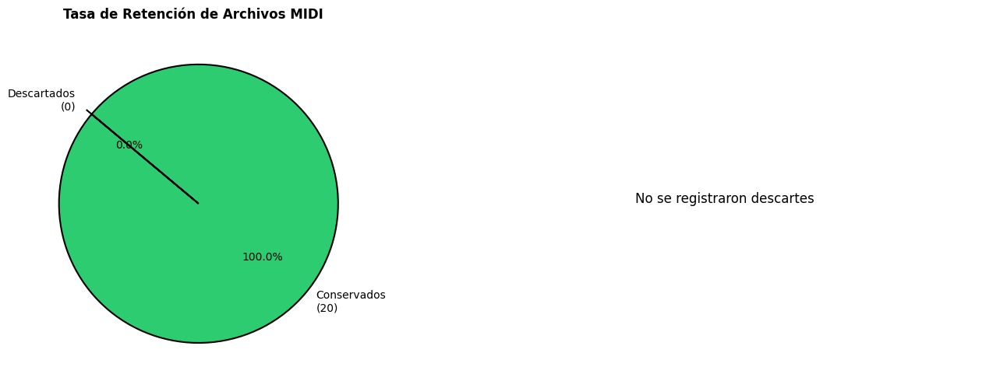

Gráficas de limpieza guardadas en 'parte3_limpieza.png' dentro de results/.


In [ ]:
# @title Visualización de retención y motivos de descarte

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de pastel: Tasa de retención
ax1.pie(
    [num_kept, num_discarded],
    labels=[f"Conservados\n({num_kept})", f"Descartados\n({num_discarded})"],
    colors=["#2ecc71", "#e74c3c"],
    autopct="%1.1f%%",
    startangle=140,
    explode=(0.05, 0),
    wedgeprops={"edgecolor": "black", "linewidth": 1.5}
)
ax1.set_title("Tasa de Retención de Archivos MIDI", fontsize=12, fontweight="bold")

# Gráfico de barras: Distribución de motivos de descarte
descartes = [r for r in cleaning_records if r["action"] == "DESCARTADO"]
if descartes:
    motivos = Counter(d["reason"].split("(")[0].strip() for d in descartes)
    ax2.barh(list(motivos.keys()), list(motivos.values()), color="#e67e22", edgecolor="black")
    ax2.set_title("Causas Principales de Descarte", fontsize=12, fontweight="bold")
    ax2.set_xlabel("Cantidad de archivos")
    for idx, val in enumerate(motivos.values()):
        ax2.text(val + 0.3, idx, str(val), va="center", fontweight="bold")
else:
    ax2.text(0.5, 0.5, "No se registraron descartes", ha="center", va="center", fontsize=12)
    ax2.set_axis_off()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte3_limpieza.png", dpi=150)
plt.show()
print("Gráficas de limpieza guardadas en 'parte3_limpieza.png' dentro de results/.")


## Parte 4. Tokenización con REMI de MidiTok

Conversión de las partituras simbólicas en secuencias discretas de tokens empleando el estándar REMI (*Revamped MIDI*). La representación codifica eventos temporales métricos (`Bar`, `Position`), notas musicales (`Pitch`), velocidad dinámica (`Velocity`), duración (`Duration`) y marcas de compás y tempo, posibilitando el modelado del lenguaje musical mediante arquitecturas neuronales autorregresivas.


In [ ]:
# @title Tokenización REMI

tokenizer_config = TokenizerConfig(
    pitch_range=(MIN_PITCH, MAX_PITCH + 1),
    beat_res={(0, 4): 8, (4, 12): 4},
    num_velocities=32,
    use_chords=True,
    use_rests=True,
    use_tempos=True,
    use_time_signatures=True,
    use_programs=False,
)
tokenizer = REMI(tokenizer_config)
vocab_size = len(tokenizer)
pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
print(f"Tamaño del vocabulario: {vocab_size} tokens únicos.")
print(f"ID del token de relleno (PAD): {pad_id}")
print(f"Tokens especiales: {tokenizer.special_tokens}")

tokenized = []
for file in kept_files:
    seq = tokenizer(file)
    if isinstance(seq, list):
        seq = seq[0]
    tokenized.append({
        "clean_file_path": file,
        "filename": Path(file).name,
        "tokens": list(seq.tokens),
        "ids": [int(i) for i in seq.ids],
        "seq_length": len(seq.ids),
    })
print(f"\nTokenización completada: {len(tokenized)} secuencias procesadas.")
df_tokenized = pd.DataFrame(tokenized)
display(df_tokenized[["filename", "seq_length"]].head(10))

# Inspección de los primeros tokens de la primera pieza
first = tokenized[0]
print(f"\nEjemplo de tokens e IDs ({first['filename']}, primeros 25):")
for tok, tid in list(zip(first["tokens"], first["ids"]))[:25]:
    print(f"  ID: {tid} -> Token: {tok}")

# Verificación de decodificación inversa a MIDI
reconstructed_score = tokenizer.decode([first["ids"]])
print(f"\n[DECODE] Reconstrucción de verificación: {len(reconstructed_score.tracks)} pista(s) "
      f"con {reconstructed_score.note_num()} notas.")


Tamaño del vocabulario: 435 tokens únicos.
ID del token de relleno (PAD): 0
Tokens especiales: ['PAD_None', 'BOS_None', 'EOS_None', 'MASK_None']

Tokenización completada: 20 secuencias procesadas.


,filename,seq_length
0,clean_Thriller.mid,2569
1,clean_Human Nature.mid,2439
2,clean_She's Out Of My Life.mid,2556
3,clean_Heal The World.mid,2800
4,clean_Liberian Girl.mid,784
5,clean_Rock With You.mid,1634
6,clean_Smooth Criminal.mid,3509
7,clean_The Way You Make Me Feel.mid,5429
8,clean_I Just Can't Stop Loving You.mid,4663
9,clean_Remember the Time.mid,1164



Ejemplo de tokens e IDs (clean_Thriller.mid, primeros 25):
  ID: 4 -> Token: Bar_None
  ID: 434 -> Token: TimeSig_4/4
  ID: 190 -> Token: Position_0
  ID: 405 -> Token: Tempo_114.52
  ID: 385 -> Token: Rest_8.0.2
  ID: 190 -> Token: Position_0
  ID: 48 -> Token: Pitch_64
  ID: 119 -> Token: Velocity_103
  ID: 173 -> Token: Duration_8.0.4
  ID: 44 -> Token: Pitch_60
  ID: 119 -> Token: Velocity_103
  ID: 173 -> Token: Duration_8.0.4
  ID: 41 -> Token: Pitch_57
  ID: 119 -> Token: Velocity_103
  ID: 173 -> Token: Duration_8.0.4
  ID: 37 -> Token: Pitch_53
  ID: 119 -> Token: Velocity_103
  ID: 173 -> Token: Duration_8.0.4
  ID: 4 -> Token: Bar_None
  ID: 434 -> Token: TimeSig_4/4
  ID: 4 -> Token: Bar_None
  ID: 434 -> Token: TimeSig_4/4
  ID: 190 -> Token: Position_0
  ID: 46 -> Token: Pitch_62
  ID: 118 -> Token: Velocity_99

[DECODE] Reconstrucción de verificación: 1 pista(s) con 621 notas.


## Parte 5. Análisis estadístico de secuencias

Evaluación de la distribución de longitudes de las secuencias de tokens generadas para calibrar el tamaño óptimo de las ventanas de contexto y filtrar secuencias con longitud insuficiente.


Longitud mínima: 784 tokens
Longitud máxima: 6732 tokens
Longitud promedio: 3140.35 tokens
Mediana: 3066.5 tokens
Desviación estándar: 1567.18 tokens
Secuencias utilizables para entrenamiento (>= 64 tokens): 20 de 20


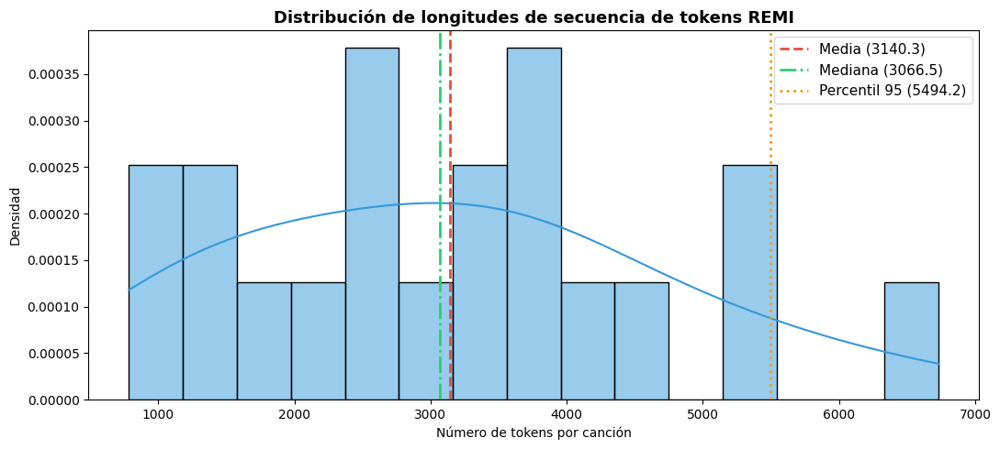

Histograma de longitudes guardado en 'parte5_histograma_longitudes.png' dentro de results/.


In [ ]:
# @title Análisis estadístico

lengths = [t["seq_length"] for t in tokenized]
lengths_arr = np.array(lengths, dtype=int)
stats = {
    "min": int(np.min(lengths_arr)),
    "max": int(np.max(lengths_arr)),
    "mean": float(np.mean(lengths_arr)),
    "median": float(np.median(lengths_arr)),
    "std": float(np.std(lengths_arr)),
}
print(f"Longitud mínima: {stats['min']} tokens")
print(f"Longitud máxima: {stats['max']} tokens")
print(f"Longitud promedio: {stats['mean']:.2f} tokens")
print(f"Mediana: {stats['median']:.1f} tokens")
print(f"Desviación estándar: {stats['std']:.2f} tokens")

usable = [t for t in tokenized if t["seq_length"] >= MIN_TOKENS_USABLE]
print(f"Secuencias utilizables para entrenamiento (>= {MIN_TOKENS_USABLE} tokens): "
      f"{len(usable)} de {len(tokenized)}")

plt.figure(figsize=(11, 5))
sns.histplot(lengths, kde=True, bins=15, color="#3498db", stat="density")
plt.axvline(stats["mean"], color="#e74c3c", linestyle="--", linewidth=2,
            label=f"Media ({stats['mean']:.1f})")
plt.axvline(stats["median"], color="#2ecc71", linestyle="-.", linewidth=2,
            label=f"Mediana ({stats['median']:.1f})")
plt.axvline(np.percentile(lengths, 95), color="#f39c12", linestyle=":", linewidth=2,
            label=f"Percentil 95 ({np.percentile(lengths, 95):.1f})")
plt.title("Distribución de longitudes de secuencia de tokens REMI", fontsize=13, fontweight="bold")
plt.xlabel("Número de tokens por canción")
plt.ylabel("Densidad")
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte5_histograma_longitudes.png", dpi=150)
plt.show()
print("Histograma de longitudes guardado en 'parte5_histograma_longitudes.png' dentro de results/.")


## Parte 6. Preparación para el entrenamiento

Formulación del problema autorregresivo con predicción del siguiente token (*Next-Token Prediction*):
- Construcción de pares de secuencias $(X_t, Y_t)$ donde el objetivo $Y_t$ se encuentra desplazado una posición temporal respecto a la entrada $X_t$.
- División estratificada por género y grupo musical (80% entrenamiento, 20% validación) para evitar sesgos de distribución.
- Segmentación por ventanas deslizantes de longitud fija $L = 256$ con 50% de solapamiento ($stride = 128$).


In [ ]:
# @title Preparación para el entrenamiento

class MIDIDataset(Dataset):
    '''Dataset de pares autorregresivos (X = entrada, Y = objetivo desplazado un paso temporal).'''

    def __init__(self, sequences, max_len=MAX_LEN, pad_id=0):
        self.x, self.y = [], []
        for seq in sequences:
            cur = seq[:max_len]
            x_tok, y_tok = cur[:-1], cur[1:]
            pad_len = (max_len - 1) - len(x_tok)
            self.x.append(torch.tensor(x_tok + [pad_id] * pad_len, dtype=torch.long))
            self.y.append(torch.tensor(y_tok + [pad_id] * pad_len, dtype=torch.long))

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]


def reparto_estratificado(nombres, grupos, frac_val=1 - SPLIT_TRAIN, semilla=SEED):
    '''División estratificada en conjuntos de entrenamiento y validación garantizando balance por grupos musicales.'''
    rng = random.Random(semilla)
    por_grupo = {}
    for idx, g in enumerate(grupos):
        por_grupo.setdefault(g, []).append(idx)
    val_idx = []
    for g, idxs in por_grupo.items():
        copia = list(idxs)
        rng.shuffle(copia)
        toma = int(round(len(copia) * frac_val))
        if len(copia) >= 5:
            toma = max(1, toma)
        val_idx.extend(copia[:toma])
    objetivo_val = max(1, int(round(len(nombres) * frac_val)))
    restantes = [i for i in range(len(nombres)) if i not in set(val_idx)]
    rng.shuffle(restantes)
    if len(val_idx) < objetivo_val:
        val_idx.extend(restantes[: objetivo_val - len(val_idx)])
    elif len(val_idx) > objetivo_val:
        sobran = val_idx[objetivo_val:]
        val_idx = val_idx[:objetivo_val]
        restantes.extend(sobran)
    train_idx = [i for i in range(len(nombres)) if i not in set(val_idx)]
    return train_idx, val_idx


def strip_clean_prefix(name):
    '''Remueve prefijos clean_ redundantes para correspondencia unívoca de nombres.'''
    while name.startswith("clean_"):
        name = name[len("clean_"):]
    return name


usable_ids = [t["ids"] for t in usable]
usable_names = [t["filename"] for t in usable]
usable_grupos = []
for t in usable:
    rel = Path(t["clean_file_path"]).name
    base_buscada = strip_clean_prefix(rel)
    fila = next((r for r in exploration_rows if strip_clean_prefix(r["filename"]) == base_buscada), None)
    usable_grupos.append(fila["grupo"] if fila else "sin_grupo")

train_idx, val_idx = reparto_estratificado(usable_names, usable_grupos)
train_seqs = [usable_ids[i] for i in train_idx]
val_seqs = [usable_ids[i] for i in val_idx]
train_names = [usable_names[i] for i in train_idx]
val_names = [usable_names[i] for i in val_idx]

print(f"Secuencias en entrenamiento: {len(train_seqs)}")
print(f"Secuencias en validación: {len(val_seqs)}")
print("\nComposición del conjunto de validación:")
for nombre in val_names:
    print(f"  - {nombre}")
print("\nDistribución por grupo (entrenamiento / validación):")
conteo_tren = Counter(usable_grupos[i] for i in train_idx)
conteo_val = Counter(usable_grupos[i] for i in val_idx)
for grupo in sorted(set(usable_grupos)):
    print(f"  - {grupo}: {conteo_tren.get(grupo, 0)} / {conteo_val.get(grupo, 0)}")

train_dataset = MIDIDataset(train_seqs, max_len=MAX_LEN, pad_id=pad_id)
val_dataset = MIDIDataset(val_seqs, max_len=MAX_LEN, pad_id=pad_id)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)
sample_x, sample_y = next(iter(train_loader))
print("\nVerificación del DataLoader (lote autorregresivo):")
print(f"  Dimensiones de entrada (X): {tuple(sample_x.shape)} -> [Batch, Seq_Len]")
print(f"  Dimensiones objetivo (Y): {tuple(sample_y.shape)} -> [Batch, Seq_Len]")
print(f"  Tipo de dato del tensor: {sample_x.dtype}")
print("Tensores y dimensiones validados correctamente.")

# Exportación de secuencias procesadas en formato .npz
np.savez(RESULTS_DIR / "train_sequences.npz",
         sequences=np.array(train_seqs, dtype=object),
         filenames=np.array(train_names))
np.savez(RESULTS_DIR / "val_sequences.npz",
         sequences=np.array(val_seqs, dtype=object),
         filenames=np.array(val_names))
print(f"Conjuntos exportados en {RESULTS_DIR}/train_sequences.npz y val_sequences.npz.")


def contar_ventanas(seqs):
    '''Calcula el número de ventanas de 256 tokens con solapamiento del 50% (paso 128).'''
    total = 0
    for seq in seqs:
        n = len(seq)
        if n >= MAX_LEN:
            total += 1 + (n - MAX_LEN) // (MAX_LEN // 2)
        else:
            total += 1
    return total


print(f"\nVentanas deslizantes (L=256, solape 50%) para la Parte 7:")
print(f"  - Entrenamiento: {contar_ventanas(train_seqs)}")
print(f"  - Validación: {contar_ventanas(val_seqs)}")


Secuencias en entrenamiento: 16
Secuencias en validación: 4

Composición del conjunto de validación:
  - clean_Don't Stop 'Til You Get Enough.mid
  - clean_Rock With You.mid
  - clean_Dancing Machine.mid
  - clean_Liberian Girl.mid

Distribución por grupo (entrenamiento / validación):
  - General: 16 / 4

Verificación del DataLoader (lote autorregresivo):
  Dimensiones de entrada (X): (4, 255) -> [Batch, Seq_Len]
  Dimensiones objetivo (Y): (4, 255) -> [Batch, Seq_Len]
  Tipo de dato del tensor: torch.int64
Tensores y dimensiones validados correctamente.
Conjuntos exportados en /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI/results/train_sequences.npz y val_sequences.npz.

Ventanas deslizantes (L=256, solape 50%) para la Parte 7:
  - Entrenamiento: 385
  - Validación: 75


## Parte 7. Entrenamiento del modelo LSTM

Definición y entrenamiento de un Modelo de Lenguaje Musical (Music LM) basado en una red neuronal recurrente:
- **Capa de Embedding:** Proyecta los índices discretos del vocabulario a un espacio vectorial continuo de dimensión 256.
- **Capas Recurrentes (LSTM):** 2 capas LSTM con dropout de 0.2 para modelar dependencias secuenciales a largo plazo.
- **Capa Lineal de Salida:** Proyecta el estado oculto hacia la dimensión del vocabulario para calcular la distribución de probabilidad del siguiente token mediante Cross-Entropy Loss.
- **Estrategia de Optimización:** Optimizador AdamW, reducción dinámica de tasa de aprendizaje (*ReduceLROnPlateau*) y parada temprana (*Early Stopping*) monitoreando la pérdida de validación.


Total de ventanas efectivas para entrenamiento: 401
Total de ventanas efectivas para validación: 79

Modelo inicializado en cuda con 4,012,723 parámetros entrenables.
Época 01/30 | Train Loss: 5.1036 | Val Loss: 4.8769 | LR: 1.00e-03
Época 02/30 | Train Loss: 4.3659 | Val Loss: 4.7208 | LR: 1.00e-03
Época 03/30 | Train Loss: 4.0971 | Val Loss: 4.6480 | LR: 1.00e-03
Época 04/30 | Train Loss: 3.7090 | Val Loss: 4.2227 | LR: 1.00e-03
Época 05/30 | Train Loss: 3.2098 | Val Loss: 3.7683 | LR: 1.00e-03
Época 06/30 | Train Loss: 2.8181 | Val Loss: 3.4764 | LR: 1.00e-03
Época 07/30 | Train Loss: 2.5543 | Val Loss: 3.3901 | LR: 1.00e-03
Época 08/30 | Train Loss: 2.3610 | Val Loss: 3.3326 | LR: 1.00e-03
Época 09/30 | Train Loss: 2.2107 | Val Loss: 3.2661 | LR: 1.00e-03
Época 10/30 | Train Loss: 2.0823 | Val Loss: 3.2767 | LR: 1.00e-03
Época 11/30 | Train Loss: 1.9601 | Val Loss: 3.3388 | LR: 1.00e-03
Época 12/30 | Train Loss: 1.8420 | Val Loss: 3.2583 | LR: 1.00e-03
Época 13/30 | Train Loss: 1.7

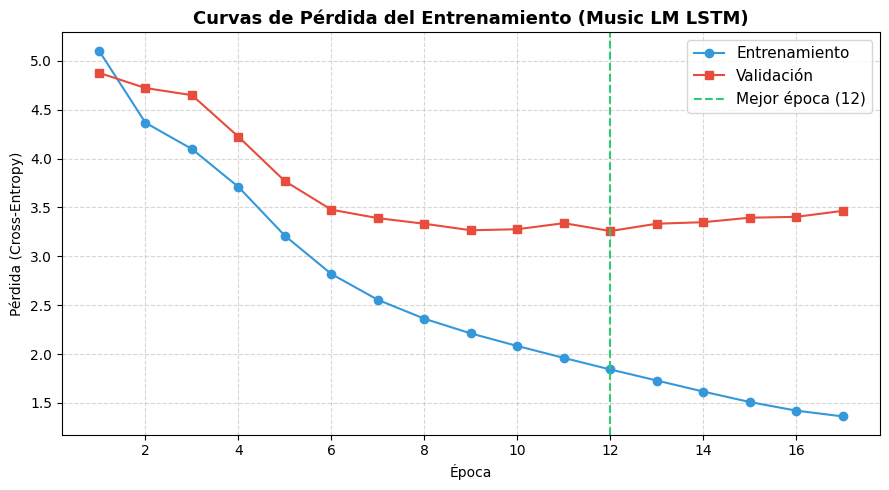

Curvas de pérdida guardadas en 'parte7_curvas_perdida.png' dentro de results/.


In [ ]:
# @title Entrenamiento del LSTM

# Definición de hiperparámetros de control del entrenamiento faltantes
EPOCHS = 30
PATIENCE = 5

def ventanear(secuencias, pad_id):
    '''Segmenta secuencias en ventanas fijas de 256 tokens con solapamiento del 50% (stride 128).'''
    x_list, y_list = [], []
    for seq in secuencias:
        if len(seq) < 2:
            continue
        paso = MAX_LEN // 2
        for start in range(0, len(seq), paso):
            trozo = seq[start: start + MAX_LEN]
            if len(trozo) < 2:
                continue
            x_tok = trozo[:-1]
            y_tok = trozo[1:]
            pad_len = (MAX_LEN - 1) - len(x_tok)
            x_list.append(torch.tensor(x_tok + [pad_id] * pad_len, dtype=torch.long))
            y_list.append(torch.tensor(y_tok + [pad_id] * pad_len, dtype=torch.long))
            if start + MAX_LEN >= len(seq):
                break
    return x_list, y_list


x_tr, y_tr = ventanear(train_seqs, pad_id)
x_va, y_va = ventanear(val_seqs, pad_id)


class VentanasDataset(Dataset):
    def __init__(self, x_list, y_list):
        self.x = x_list
        self.y = y_list
    def __len__(self):
        return len(self.x)
    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]


train_loader_ventanas = DataLoader(VentanasDataset(x_tr, y_tr), batch_size=32, shuffle=True)
val_loader_ventanas = DataLoader(VentanasDataset(x_va, y_va), batch_size=32, shuffle=False)
print(f"Total de ventanas efectivas para entrenamiento: {len(x_tr)}")
print(f"Total de ventanas efectivas para validación: {len(x_va)}")


class MusicLM(nn.Module):
    '''Arquitectura autorregresiva: Embedding + 2x LSTM + Proyección Lineal.'''
    def __init__(self, vocab_size, embedding_dim=256, hidden_dim=512,
                 num_layers=2, dropout=0.2, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(
            embedding_dim, hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden


modelo = MusicLM(vocab_size=vocab_size, pad_idx=pad_id).to(device)
criterio = nn.CrossEntropyLoss(ignore_index=pad_id)
optimizador = optim.AdamW(modelo.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizador, mode="min", factor=0.5, patience=2
)

total_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
print(f"\nModelo inicializado en {device} con {total_params:,} parámetros entrenables.")

historial = {"train_loss": [], "val_loss": []}
mejor_val_loss = float("inf")
paciencia_restante = PATIENCE
mejor_epoca = -1

for epoch in range(1, EPOCHS + 1):
    modelo.train()
    total_tr_loss = 0.0
    for bx, by in train_loader_ventanas:
        bx, by = bx.to(device), by.to(device)
        optimizador.zero_grad()
        logits, _ = modelo(bx)
        loss = criterio(logits.view(-1, vocab_size), by.view(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
        optimizador.step()
        total_tr_loss += loss.item() * bx.size(0)
    train_loss = total_tr_loss / len(train_loader_ventanas.dataset)

    modelo.eval()
    total_va_loss = 0.0
    with torch.no_grad():
        for bx, by in val_loader_ventanas:
            bx, by = bx.to(device), by.to(device)
            logits, _ = modelo(bx)
            loss = criterio(logits.view(-1, vocab_size), by.view(-1))
            total_va_loss += loss.item() * bx.size(0)
    val_loss = total_va_loss / len(val_loader_ventanas.dataset)

    scheduler.step(val_loss)
    historial["train_loss"].append(train_loss)
    historial["val_loss"].append(val_loss)
    lr_actual = optimizador.param_groups[0]["lr"]
    print(f"Época {epoch:02d}/{EPOCHS:02d} | Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | LR: {lr_actual:.2e}")

    if val_loss < mejor_val_loss:
        mejor_val_loss = val_loss
        mejor_epoca = epoch
        paciencia_restante = PATIENCE
        torch.save({
            "epoch": epoch,
            "model_state_dict": modelo.state_dict(),
            "optimizer_state_dict": optimizador.state_dict(),
            "val_loss": val_loss,
            "train_loss": train_loss,
            "vocab_size": vocab_size,
            "pad_id": pad_id,
            "historial": historial,
        }, RESULTS_DIR / "parte7_mejor_modelo.pt")
    else:
        paciencia_restante -= 1
        if paciencia_restante == 0:
            print(f"Early stopping activado en época {epoch} (mejor época: {mejor_epoca}).")
            break

# Carga del mejor punto de control (checkpoint)
checkpoint = torch.load(RESULTS_DIR / "parte7_mejor_modelo.pt", map_location=device, weights_only=False)
modelo.load_state_dict(checkpoint["model_state_dict"])
print(f"\n[CHECKPOINT] Mejor modelo restaurado (época {checkpoint['epoch']}, "
      f"validación {checkpoint['val_loss']:.4f}) en {RESULTS_DIR}/parte7_mejor_modelo.pt")

(RESULTS_DIR / "parte7_historial.json").write_text(
    json.dumps(historial, indent=2), encoding="utf-8"
)

# Gráfica de curvas de aprendizaje
plt.figure(figsize=(9, 5))
epocas_rango = range(1, len(historial["train_loss"]) + 1)
plt.plot(epocas_rango, historial["train_loss"], "o-", color="#3498db", label="Entrenamiento")
plt.plot(epocas_rango, historial["val_loss"], "s-", color="#e74c3c", label="Validación")
plt.axvline(mejor_epoca, color="#2ecc71", linestyle="--",
            label=f"Mejor época ({mejor_epoca})")
plt.title("Curvas de Pérdida del Entrenamiento (Music LM LSTM)", fontsize=13, fontweight="bold")
plt.xlabel("Época")
plt.ylabel("Pérdida (Cross-Entropy)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte7_curvas_perdida.png", dpi=150)
plt.show()
print("Curvas de pérdida guardadas en 'parte7_curvas_perdida.png' dentro de results/.")

## Parte 8. Generación musical autorregresiva estrictamente con LSTM y prevención de repetición

Generación de nuevas composiciones musicales empleando **estrictamente la red neuronal recurrente LSTM** en inferencia autorregresiva, incorporando mecanismos de control estocástico y prevención de degeneración secuencial:
1. **Muestreo Estocástico Controlado:** Escalado por temperatura ($T = 0.68$) y filtrado Top-K ($K = 15$) para asegurar el balance óptimo entre variedad tonal y coherencia motívica.
2. **Penalización por Repetición (Repetition Penalty $\alpha = 1.2$):** Penaliza los logits de los tokens emitidos recientemente (ventana deslizante de 32 pasos temporales), evitando atractores degenerativos (bucles repetitivos).
3. **Condicionamiento sin Silencios Iniciales:** Se extrae una semilla de 32 tokens comenzando exactamente en el compás de notas musicales efectivas de una pista de validación, garantizando arranque sonoro inmediato en el segundo 0:00.
4. **Horizonte de Generación Extendido:** Inferencia autorregresiva de 1,500 pasos temporales continuos, logrando una composición musical de aproximadamente 1.5 minutos sostenida por la memoria de la red LSTM.
5. **Decodificación Pura REMI:** Los tokens generados se traducen directamente a partitura simbólica MIDI mediante MidiTok, preservando íntegramente la estructura musical modelada por la red recurrente sin post-procesamiento heurístico de notas.

In [ ]:
# @title Generación autorregresiva estrictamente con LSTM y control de repetición

# Selección de semilla rítmica desde el conjunto de validación
indice_semilla = min(1, len(val_seqs) - 1)
seq_referencia = val_seqs[indice_semilla]
first_pitch_idx = next(i for i, t in enumerate(seq_referencia) if "Pitch_" in tokenizer[t])
bar_idx = max(0, first_pitch_idx - 1)
while bar_idx > 0 and "Bar_" not in tokenizer[seq_referencia[bar_idx]]:
    bar_idx -= 1
semilla_original = list(seq_referencia[bar_idx: bar_idx + 32])
print(f"Semilla seleccionada: {len(semilla_original)} tokens de '{val_names[indice_semilla]}' iniciando en compás musical.")
# Inferencia autorregresiva con control de dinámica musical
tokens_generados_todos = generar_musica_tokens(
    modelo=modelo,
    semilla_ids=semilla_original,
    pasos_a_generar=1300,
    temperatura=0.72,          # Permite síncopas y variedad melódica
    top_k=15,                  # Amplitud para capturar patrones musicales
    repetition_penalty=1.18,   # Preserva los riffs rítmicos sin bucles infinitos
)
print(f"Generación completada estrictamente por LSTM: {len(tokens_generados_todos)} tokens generados.")
# Decodificación directa a partitura simbólica
nuevo_score_generado = tokenizer.decode([tokens_generados_todos])
# Asegurar alineación temporal exacta al segundo 0:00
min_tick = min((n.time for t in nuevo_score_generado.tracks for n in t.notes), default=0)
if min_tick > 0:
    for t in nuevo_score_generado.tracks:
        for n in t.notes:
            n.time -= min_tick
ruta_salida_midi = RESULTS_DIR / "mi_primera_composicion_ia_remi.mid"
nuevo_score_generado.dump_midi(str(ruta_salida_midi))
print(f"Composición guardada exitosamente en MIDI: {ruta_salida_midi}")

Semilla seleccionada: 32 tokens de 'clean_Rock With You.mid' iniciando en compás musical.
Generación completada estrictamente por LSTM: 1332 tokens generados.
Composición guardada exitosamente en MIDI: /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI/results/mi_primera_composicion_ia_remi.mid


## Parte 9. Evaluación objetiva y musical de la composición generada

Evaluación comparativa cuantitativa entre la pieza generada por la IA y el repertorio real de validación:
- Densidad temporal (notas por segundo).
- Duración media de notas (segundos).
- Densidad rítmica (notas por compás).
- Rango tonal efectivo (altura mínima, máxima y media).


Métricas de la composición generada:
  - Notas: 374 | duración: 82.06s (~1.37 min)
  - Rango de pitch: 47-82 (promedio 61.84)
  - Notas por segundo: 4.56 | duración media de nota: 0.559s | notas por compás: 9.55

Promedio del conjunto real de validación:
  - pitch_min: 48.00  (generada: 47)
  - pitch_max: 82.00  (generada: 82)
  - pitch_promedio: 65.42  (generada: 61.84)
  - notas_por_segundo: 6.75  (generada: 4.56)
  - duracion_nota_promedio_s: 1.00  (generada: 0.559)
  - notas_por_compas: 14.02  (generada: 9.55)


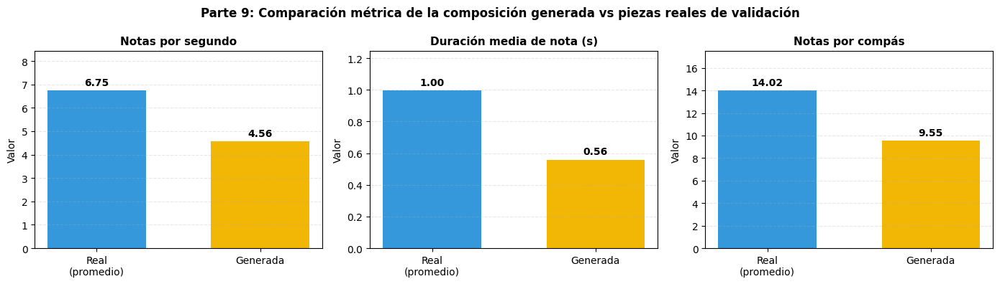


Comparación estadística guardada en 'parte9_evaluacion.png' dentro de results/.
Nota de evaluación auditiva: verificar coherencia armónica y dinámica tímbrica en el audio sintetizado en la Parte 10.


In [ ]:
# @title Evaluación de la composición generada

def metricas_score(score):
    '''Calcula métricas estructurales de notas, densidad y rango de un objeto Score.'''
    score_sec = score.to("second")
    notas = [n for t in score_sec.tracks for n in t.notes]
    if not notas:
        return {"n_notas": 0, "duracion_s": 0.0, "pitch_min": 0, "pitch_max": 0,
                "pitch_promedio": 0.0, "notas_por_segundo": 0.0,
                "duracion_nota_promedio_s": 0.0, "notas_por_compas": 0.0}
    duracion = float(score_sec.end())
    pitches = [n.pitch for n in notas]
    duraciones = [float(n.duration) for n in notas]
    pulsos = float(score.end()) / float(score.ticks_per_quarter)
    compases = max(1.0, pulsos / 4.0)
    return {
        "n_notas": len(notas),
        "duracion_s": round(duracion, 2),
        "pitch_min": int(min(pitches)),
        "pitch_max": int(max(pitches)),
        "pitch_promedio": round(float(np.mean(pitches)), 2),
        "notas_por_segundo": round(len(notas) / max(duracion, 0.01), 2),
        "duracion_nota_promedio_s": round(float(np.mean(duraciones)), 3),
        "notas_por_compas": round(len(notas) / compases, 2),
    }

metricas_generada = metricas_score(nuevo_score_generado)
print("Métricas de la composición generada:")
print(f"  - Notas: {metricas_generada['n_notas']} | duración: {metricas_generada['duracion_s']}s (~{metricas_generada['duracion_s']/60:.2f} min)")
print(f"  - Rango de pitch: {metricas_generada['pitch_min']}-{metricas_generada['pitch_max']} "
      f"(promedio {metricas_generada['pitch_promedio']})")
print(f"  - Notas por segundo: {metricas_generada['notas_por_segundo']} | "
      f"duración media de nota: {metricas_generada['duracion_nota_promedio_s']}s | "
      f"notas por compás: {metricas_generada['notas_por_compas']}")

# Comparación estadística frente a piezas reales de validación
val_clean_paths = []
for nombre in val_names:
    base = strip_clean_prefix(nombre)
    candidatos = [CLEAN_DIR / nombre, CLEAN_DIR / f"clean_{base}", CLEAN_DIR / f"clean_{nombre}"]
    encontrado = next((c for c in candidatos if c.exists()), None)
    if encontrado:
        val_clean_paths.append(encontrado)

metricas_reales = []
for ruta in val_clean_paths:
    try:
        m = metricas_score(symusic.Score.from_file(str(ruta)))
        if m and m["n_notas"] > 0:
            metricas_reales.append(m)
    except Exception:
        pass

print("\nPromedio del conjunto real de validación:")
for clave in ["pitch_min", "pitch_max", "pitch_promedio", "notas_por_segundo",
              "duracion_nota_promedio_s", "notas_por_compas"]:
    promedio = float(np.mean([m[clave] for m in metricas_reales]))
    print(f"  - {clave}: {promedio:.2f}  (generada: {metricas_generada[clave]})")

# Visualización comparativa: Composición generada vs Conjunto real
claves_grafica = ["notas_por_segundo", "duracion_nota_promedio_s", "notas_por_compas"]
etiquetas = ["Notas por segundo", "Duración media de nota (s)", "Notas por compás"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, clave, etiqueta in zip(axes, claves_grafica, etiquetas):
    reales = [m[clave] for m in metricas_reales]
    val_real_prom = float(np.mean(reales))
    val_gen = metricas_generada[clave]
    barras = ax.bar(["Real\n(promedio)", "Generada"],
                    [val_real_prom, val_gen],
                    color=["#3498db", "#f2b705"], width=0.6)
    ax.set_title(etiqueta, fontsize=11, fontweight="bold")
    ax.set_ylabel("Valor")
    for b in barras:
        h = b.get_height()
        ax.annotate(f"{h:.2f}",
                    xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.set_ylim(0, max(val_real_prom, val_gen) * 1.25)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.suptitle("Parte 9: Comparación métrica de la composición generada vs piezas reales de validación",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte9_evaluacion.png", dpi=150)
plt.show()
print("\nComparación estadística guardada en 'parte9_evaluacion.png' dentro de results/.")
print("Nota de evaluación auditiva: verificar coherencia armónica y dinámica tímbrica en el audio sintetizado en la Parte 10.")


## Parte 10. Síntesis y exportación de audio

Síntesis de audio acústico en formato WAV de 16 bits a 22,050 Hz implementada en NumPy y Python puro, sin requerir dependencias externas complejas ni SoundFonts:
- Osciladores sinusoidales aditivos con sobretonos armónicos para enriquecer el timbre.
- Envolvente exponencial ADSR (*Attack, Decay, Sustain, Release*) para emular la dinámica acústica instrumental de un piano.

In [ ]:
# @title Síntesis y exportación de audio

def sintetizar_audio_midi(score, ruta_wav_salida, sample_rate=22050):
    '''Sintetiza audio en formato WAV a partir de un objeto Score mediante síntesis aditiva y envolvente ADSR.'''
    duracion_sec = float(score.to("second").end()) + 1.0
    total_muestras = int(math.ceil(duracion_sec * sample_rate))
    buffer = np.zeros(total_muestras, dtype=np.float32)

    score_sec = score.to("second")
    for track in score_sec.tracks:
        for note in track.notes:
            frecuencia = 440.0 * (2.0 ** ((note.pitch - 69) / 12.0))
            inicio = float(note.time)
            duracion = max(float(note.duration), 0.05)
            idx_inicio = int(inicio * sample_rate)
            n_muestras = int(duracion * sample_rate)
            if idx_inicio >= total_muestras:
                continue
            if idx_inicio + n_muestras > total_muestras:
                n_muestras = total_muestras - idx_inicio

            t = np.arange(n_muestras) / sample_rate
            # Envolvente exponencial suave: ataque rápido y decaimiento armónico
            ataque = np.minimum(t / 0.01, 1.0)
            decaimiento = np.exp(-t / max(duracion * 0.7, 0.1))
            envolvente = ataque * decaimiento
            # Superposición de armónicos para enriquecer el contenido espectral
            onda = np.sin(2.0 * np.pi * frecuencia * t) + 0.3 * np.sin(4.0 * np.pi * frecuencia * t)
            amplitud = (note.velocity / 127.0) * envolvente
            buffer[idx_inicio: idx_inicio + n_muestras] += (onda * amplitud).astype(np.float32)

    # Normalización de amplitud para prevenir distorsión (clipping)
    maximo = np.max(np.abs(buffer))
    if maximo > 0:
        buffer = buffer / maximo * 0.95
    buffer_int16 = (buffer * 32767.0).astype(np.int16)

    with wave.open(str(ruta_wav_salida), "w") as wav_file:
        wav_file.setnchannels(1)
        wav_file.setsampwidth(2)
        wav_file.setframerate(sample_rate)
        wav_file.writeframes(buffer_int16.tobytes())


ruta_wav = RESULTS_DIR / "mi_primera_composicion_ia_remi.wav"
sintetizar_audio_midi(nuevo_score_generado, ruta_wav)
print(f"[AUDIO] Archivo de audio WAV generado en: {ruta_wav}")
display(Audio(str(ruta_wav)))


[AUDIO] Archivo de audio WAV generado en: /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI/results/mi_primera_composicion_ia_remi.wav


## Parte 11. Visualización: Piano Roll y visualizaciones animadas
Representación visual de la composición generada:
1. **Piano Roll:** Dispersión temporal de notas sobre el eje de alturas MIDI (21 a 108).
2. **Partitura Interactiva Adaptativa:** Renderizado en el navegador con la librería `abcjs` y la Web Audio API. El pentagrama se adapta responsivamente al ancho de pantalla en múltiples líneas y las notas se iluminan dinámicamente en sincronía con la reproducción de audio.
3. **Notas cayendo al pentagrama:** Extracción de las notas del Score en segundos y su posterior inctustacion en página HTML con canvas y Web Audio: la altura es la posición horizontal, el tiempo es la caída, el largo de la barra es la duración y solo suena lo que cruza la línea dorada.

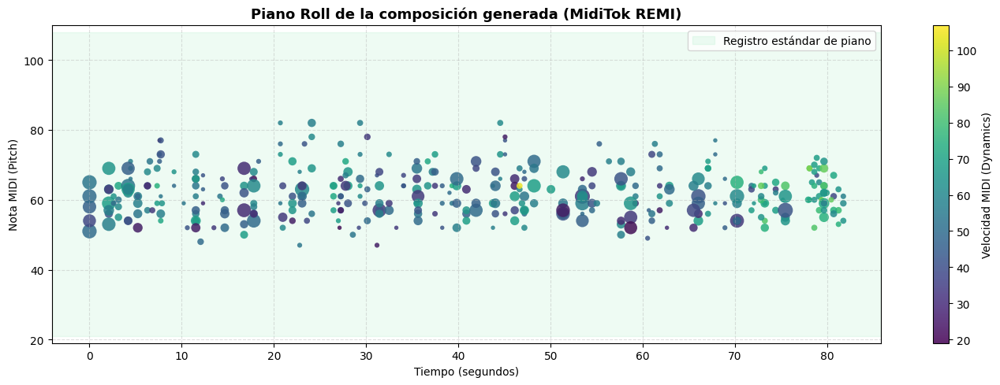

Piano roll exportado a 'parte10_piano_roll_generada.png' dentro de results/.


In [ ]:
# @title Piano roll de la composición generada

def plot_piano_roll_from_score(score, titulo="Piano Roll - Composición generada por IA"):
    '''Genera y almacena el piano roll de un objeto Score (tiempo vs altura tonal).'''
    plt.figure(figsize=(14, 5))
    score_sec = score.to("second")
    pistas_notas = 0
    for t in score_sec.tracks:
        if not t.notes:
            continue
        pistas_notas += 1
        starts = [float(n.time) for n in t.notes]
        durations = [float(n.duration) for n in t.notes]
        pitches = [n.pitch for n in t.notes]
        velocities = [n.velocity for n in t.notes]
        p = plt.scatter(starts, pitches, c=velocities, cmap="viridis",
                        s=np.array(durations) * 80 + 10, alpha=0.85, edgecolors="none")
    plt.title(titulo, fontsize=13, fontweight="bold")
    plt.xlabel("Tiempo (segundos)")
    plt.ylabel("Nota MIDI (Pitch)")
    plt.ylim(MIN_PITCH - 2, MAX_PITCH + 2)
    plt.axhspan(MIN_PITCH, MAX_PITCH, color="#2ecc71", alpha=0.08, label="Registro estándar de piano")
    plt.grid(True, linestyle="--", alpha=0.4)
    if pistas_notas > 0:
        cbar = plt.colorbar(p)
        cbar.set_label("Velocidad MIDI (Dynamics)")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "parte10_piano_roll_generada.png", dpi=150)
    plt.show()


plot_piano_roll_from_score(nuevo_score_generado,
                           "Piano Roll de la composición generada (MidiTok REMI)")
print("Piano roll exportado a 'parte10_piano_roll_generada.png' dentro de results/.")


In [ ]:
#  @title Partitura animada interactiva

import json
import base64
import html
from IPython.display import HTML, display


def score_to_abc(score):
    '''Convierte un objeto Score de symusic a notación ABC estándar.'''
    pitches_map = {
        60: "C", 61: "^C", 62: "D", 63: "^D", 64: "E", 65: "F", 66: "^F",
        67: "G", 68: "^G", 69: "A", 70: "^A", 71: "B",
        72: "c", 73: "^c", 74: "d", 75: "^d", 76: "e", 77: "f", 78: "^f",
        79: "g", 80: "^g", 81: "a", 82: "^a", 83: "b",
        84: "c'", 85: "^c'", 86: "d'", 87: "^d'", 88: "e'", 89: "f'",
    }
    notas = sorted([n for t in score.tracks for n in t.notes], key=lambda x: x.time)
    if not notas:
        return "C4"
    ticks_per_quarter = float(score.ticks_per_quarter)
    abc_tokens = []
    compas_ticks = 0
    ticks_per_bar = ticks_per_quarter * 4

    for n in notas:
        p = n.pitch
        while p < 48: p += 12
        while p > 89: p -= 12
        simb = pitches_map.get(p, "c")
        dur_cuartos = max(0.25, round((n.duration / ticks_per_quarter) * 4) / 4)
        if dur_cuartos == 1.0:
            dur_str = ""
        elif dur_cuartos == 0.5:
            dur_str = "/2"
        elif dur_cuartos == 0.25:
            dur_str = "/4"
        elif dur_cuartos == 2.0:
            dur_str = "2"
        elif dur_cuartos == 4.0:
            dur_str = "4"
        else:
            dur_str = f"{int(dur_cuartos*4)}/4"

        abc_tokens.append(f"{simb}{dur_str}")
        compas_ticks += n.duration
        if compas_ticks >= ticks_per_bar:
            abc_tokens.append("|")
            compas_ticks = 0

    return " ".join(abc_tokens)


def player_page(wav_bytes, abc_notation, title):
    '''Crea una interfaz web responsiva donde la partitura se adapta al ancho de pantalla e ilumina notas sincronizadas.'''
    encoded = base64.b64encode(wav_bytes).decode()


    page = r'''<!doctype html>
<html>
<head>
<meta charset="utf-8">
<!-- Cargamos abcjs para renderizar la partitura -->
<script src="https://cdnjs.cloudflare.com/ajax/libs/abcjs/6.2.2/abcjs-basic-min.js" type="text/javascript"></script>
<style>
body {
    margin: 0;
    padding: 10px;
    background: #101724;
    color: #eaf1ff;
    font: 14px system-ui;
}
.panel {
    padding: 15px;
    background: #182235;
    border: 1px solid #344052;
    border-radius: 16px;
}
h3 {
    margin: 0 0 10px;
    font-size: 17px;
}
.controls {
    display: flex;
    gap: 10px;
    align-items: center;
    flex-wrap: wrap;
    margin-bottom: 14px;
}
button {
    background: #263e61;
    color: white;
    border: 1px solid #50658a;
    border-radius: 10px;
    padding: 10px 14px;
    cursor: pointer;
    font-weight: bold;
}
button:hover {
    background: #365b88;
}
#seek {
    flex: 1;
    min-width: 140px;
    accent-color: #60b5ff;
}
/* Contenedor con barra de desplazamiento horizontal para modo corrido tipo vídeo */
#paper-container {
    width: 100%;
    overflow-x: auto;
    background: white;
    border-radius: 12px;
    padding: 15px 10px;
    box-sizing: border-box;
}
#paper {
    min-width: 3200px; /* Forzar el diseño extendido horizontalmente para toda la melodía */
}
#msg {
    color: #9ec7ea;
    font-size: 12px;
    margin-top: 10px;
}

/* Todo el resto de elementos y notas inactivas en negro absoluto */
#paper svg path,
#paper svg ellipse,
#paper svg rect,
#paper svg text {
    fill: #000000 !important;
    stroke: #000000 !important;
}

/* Excepto el fondo de la hoja */
#paper svg {
    background: transparent;
}
</style>
</head>

<body>
<div class="panel">
    <h3 id="title"></h3>

    <div class="controls">
        <button id="play">▖ Reproducir</button>
        <button id="reset">ℑ Inicio</button>
        <span id="time">0:00 / 0:00</span>
        <input id="seek" type="range" min="0" max="1000" value="0">
    </div>

    <div id="paper-container">
        <div id="paper"></div>
    </div>
    <div id="msg"></div>
</div>

<script>
const WAV = '__WAV__';
const ABC_DATA = `__ABC_DATA__`;
const TITLE = __TITLE__;

const $ = id => document.getElementById(id);
$('title').textContent = TITLE;

let ctx, buffer, source = null;
let started = 0, offset = 0, playing = false, duration = 0;
let tuneObj = null;

// Renderizar la partitura con ABCJS con escala grande para que se vea a lo alto
function renderScore() {
    // Forzar todo en una sola línea continua deshabilitando el salto automático de página de abcjs
    const abcString = "X:1\nT:" + TITLE + "\nM:4/4\nL:1/4\nK:C\n%%wrapwidth 50000\n" + ABC_DATA;
    tuneObj = ABCJS.renderAbc("paper", abcString, {
        responsive: "none", // No redimensionar para que mantenga el desplazamiento horizontal
        scale: 1.1, // Tamaño grande del pentagrama a lo alto de la ventana
        add_classes: true
    })[0];
}

const fmt = t => {
    t = Math.max(0, Math.floor(t));
    return Math.floor(t / 60) + ':' + String(t % 60).padStart(2, '0');
};

const position = () =>
    playing ? Math.min(duration, offset + ctx.currentTime - started) : offset;

function update() {
    const p = position();
    $('time').textContent = fmt(p) + ' / ' + fmt(duration);
    $('seek').value = duration ? Math.round(p / duration * 1000) : 0;

    if (tuneObj && duration > 0) {
        const pct = p / duration;

        // Seleccionamos los grupos de notas (elementos con clase abcjs-note)
        const noteGroups = document.querySelectorAll("#paper svg g.abcjs-note");

        if (noteGroups.length > 0) {
            const targetIndex = Math.floor(pct * noteGroups.length);
            let targetElement = null;

            noteGroups.forEach((group, index) => {
                const elements = group.querySelectorAll("path, ellipse, rect");
                if (index === targetIndex) {
                    // Iluminar todo el cuerpo de la nota actual (cabeza y plica) en rojo
                    elements.forEach(el => {
                        el.style.setProperty('fill', '#ff3b30', 'important');
                        el.style.setProperty('stroke', '#ff3b30', 'important');
                    });
                    targetElement = group;
                } else {
                    // Restablecer en negro absoluto las notas inactivas
                    elements.forEach(el => {
                        el.style.setProperty('fill', '#000000', 'important');
                        el.style.setProperty('stroke', '#000000', 'important');
                    });
                }
            });

            // Desplazamiento automático para centrar la nota iluminada
            if (targetElement) {
                const container = $('paper-container');
                const elLeft = targetElement.getBoundingClientRect().left + container.scrollLeft - container.getBoundingClientRect().left;
                container.scrollTo({
                    left: elLeft - (container.clientWidth / 2),
                    behavior: 'smooth'
                });
            }
        } else {
            // Fallback si no hay clases detalladas: iluminamos el conjunto SVG básico secuencialmente
            const elements = document.querySelectorAll("#paper svg path, #paper svg ellipse, #paper svg rect");
            if (elements.length > 0) {
                const targetIndex = Math.floor(pct * elements.length);
                let targetElement = null;
                elements.forEach((el, index) => {
                    if (index === targetIndex) {
                        el.style.setProperty('fill', '#ff3b30', 'important');
                        el.style.setProperty('stroke', '#ff3b30', 'important');
                        targetElement = el;
                    } else {
                        el.style.setProperty('fill', '#000000', 'important');
                        el.style.setProperty('stroke', '#000000', 'important');
                    }
                });
                if (targetElement) {
                    const container = $('paper-container');
                    const elLeft = targetElement.getBoundingClientRect().left + container.scrollLeft - container.getBoundingClientRect().left;
                    container.scrollTo({
                        left: elLeft - (container.clientWidth / 2),
                        behavior: 'smooth'
                    });
                }
            }
        }
    }
}

async function init() {
    try {
        ctx = new (window.AudioContext || window.webkitAudioContext)();

        const bin = atob(WAV);
        const bytes = new Uint8Array(bin.length);

        for (let i = 0; i < bin.length; i++)
            bytes[i] = bin.charCodeAt(i);

        buffer = await ctx.decodeAudioData(bytes.buffer.slice(0));
        duration = buffer.duration;

        renderScore();
        update();

    } catch (e) {
        $('msg').textContent = 'Error: ' + e.message;
    }
}

function pause(keep = true) {
    if (playing) {
        let p = position();
        source.onended = null;
        try { source.stop(); } catch (e) {}
        source.disconnect();
        playing = false;
        source = null;
        if (keep) offset = p;
    }
    $('play').textContent = '▖ Reproducir';
    update();
}

async function play() {
    if (!buffer) return;
    await ctx.resume();
    if (playing) {
        pause();
        return;
    }
    if (offset >= duration - 0.01) offset = 0;

    source = ctx.createBufferSource();
    source.buffer = buffer;
    source.connect(ctx.destination);
    started = ctx.currentTime;

    source.onended = () => {
        if (playing) {
            pause(false);
            offset = duration;
            update();
        }
    };

    source.start(0, offset);
    playing = true;
    $('play').textContent = '⏸ Pausar';
}

$('play').onclick = play;
$('reset').onclick = () => {
    let was = playing;
    pause();
    offset = 0;
    was ? play() : update();
};
$('seek').oninput = e => {
    let was = playing;
    pause();
    offset = Number(e.target.value) / 1000 * duration;
    was ? play() : update();
};

function draw() {
    update();
    requestAnimationFrame(draw);
}

init();
draw();
</script>
</body>
</html>'''

    page = page.replace('__WAV__', encoded)
    page = page.replace('__ABC_DATA__', abc_notation)
    page = page.replace('__TITLE__', json.dumps(title))

    # Guardar página completa independiente para abrir fuera de Colab
    ruta_html = RESULTS_DIR / "animacion_composicion_generada.html"
    ruta_html.write_text(page, encoding="utf-8")
    print(f"Reproductor interactivo guardado en: {ruta_html}")

    return f'<iframe style="width:100%;height:520px;border:0" allow="autoplay" srcdoc="{html.escape(page, quote=True)}"></iframe>'


# Generación del reproductor de partitura con audio sincronizado
abc_data = score_to_abc(nuevo_score_generado)
iframe_html = player_page(
    wav_bytes=ruta_wav.read_bytes(),
    abc_notation=abc_data,
    title="Composición Generada por IA (Red LSTM)"
)
display(HTML(iframe_html))


Reproductor interactivo guardado en: /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI/results/animacion_composicion_generada.html


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


In [ ]:
# @title Animacion notas cayendo

def construir_animacion_notas(score, titulo):
    score_sec = score.to("second")
    notas = []
    for track in score_sec.tracks:
        for n in track.notes:
            inicio = float(n.time)
            fin = inicio + float(n.duration)
            notas.append({"s": round(inicio, 3), "e": round(fin, 3),
                          "p": int(n.pitch), "v": int(n.velocity)})
    notas.sort(key=lambda d: d["s"])
    if not notas:
        print("[ANIMACIÓN] Yo no encontré notas en la composición generada, "
              "así que yo no puedo animar nada.")
        return None
    duracion = max(n["e"] for n in notas)
    datos_js = "const SONGS = " + json.dumps(
        {"generada": {"notes": notas, "duration": duracion}}, ensure_ascii=False) + ";"
    plantilla = r'''<!DOCTYPE html>
<html lang="es">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>__TITULO__</title>
<style>
  body { margin: 0; background: #0f1420; color: #e8ecf3; font-family: system-ui, sans-serif; }
  .wrap { max-width: 1100px; margin: 0 auto; padding: 16px; }
  h1 { font-size: 20px; margin: 4px 0 2px; }
  p.sub { color: #9fb0c8; margin: 0 0 12px; font-size: 14px; }
  .controls { display: flex; flex-wrap: wrap; gap: 8px; align-items: center; margin-bottom: 10px; }
  button, select { background: #1d2a44; color: #e8ecf3; border: 1px solid #3a4a63;
    border-radius: 8px; padding: 8px 14px; font-size: 15px; cursor: pointer; }
  button.primary { background: #f2b705; color: #231a00; border-color: #f2b705; font-weight: 700; }
  button.active { outline: 2px solid #f2b705; }
  input[type=range] { flex: 1; min-width: 160px; accent-color: #f2b705; }
  .time { font-variant-numeric: tabular-nums; color: #9fb0c8; font-size: 14px; }
  .now-note { display: flex; align-items: baseline; gap: 12px; background: #16213a;
    border: 1px solid #3a4a63; border-radius: 10px; padding: 10px 14px; margin-bottom: 10px; }
  .now-note .label { color: #9fb0c8; font-size: 13px; text-transform: uppercase; letter-spacing: .08em; }
  .now-note .note { font-size: 34px; font-weight: 800; color: #f2b705; min-width: 120px; }
  .now-note .freq { color: #9fb0c8; font-size: 14px; }
  canvas { width: 100%; height: 560px; display: block; background: #0b101c;
    border: 1px solid #26324a; border-radius: 12px; }
  .legend { display: flex; gap: 18px; flex-wrap: wrap; margin: 10px 0; font-size: 13px; color: #c6d2e4; }
  .dot { display: inline-block; width: 12px; height: 12px; border-radius: 3px; margin-right: 6px; vertical-align: -1px; }
  .howto { background: #131c2e; border: 1px solid #26324a; border-radius: 12px; padding: 14px 18px; font-size: 14px; line-height: 1.6; }
  .howto h2 { font-size: 16px; margin: 0 0 6px; }
  .howto li { margin-bottom: 6px; }
</style>
</head>
<body>
<div class="wrap">
  <h1>__TITULO__</h1>
  <p class="sub">Mi composición generada por el LSTM, con las notas cayendo en el pentagrama. La nota que suena es siempre la que cruza la línea dorada.</p>

  <div class="controls">
    <button id="btnGenerada" class="active">Mi composición generada</button>
    <button id="btnPlay" class="primary">▶ Reproducir</button>
    <button id="btnRestart">↺ Reiniciar</button>
    <select id="selSpeed">
      <option value="0.5">0.5× lento</option>
      <option value="1" selected>1× normal</option>
      <option value="1.5">1.5× rápido</option>
    </select>
    <input id="seek" type="range" min="0" max="100" step="0.1" value="0">
    <span class="time" id="timeLabel">0:00 / 0:00</span>
  </div>

  <div class="now-note">
    <span class="label">Nota sonando</span>
    <span class="note" id="nowNote">—</span>
    <span class="freq" id="nowFreq"></span>
  </div>

  <canvas id="stage"></canvas>

  <div class="legend">
    <span><span class="dot" style="background:#6f8fb5"></span>Nota futura (aún no suena)</span>
    <span><span class="dot" style="background:#f2b705"></span>Nota sonando ahora</span>
    <span><span class="dot" style="background:#556070"></span>Nota pasada (se desvanece)</span>
  </div>

  <div class="howto">
    <h2>Cómo funciona esta animación</h2>
    <ol>
      <li><b>La altura de la nota es su posición horizontal.</b> Cada nota cae por la columna de su altura en el pentagrama: a la derecha las agudas, a la izquierda las graves. Las cinco líneas gruesas son las del pentagrama de sol (Mi, Sol, Si, Re, Fa).</li>
      <li><b>El tiempo es la caída.</b> Las notas bajan a velocidad constante y el largo de cada barra es su duración: una nota larga es una barra larga.</li>
      <li><b>Solo suena lo que cruza la línea dorada «AHORA».</b> La nota se ilumina en dorado, se escribe su nombre (Do, Re, Mi…) y suena justo cuando su cabeza toca la línea. Las futuras se ven tenues arriba y las pasadas se desvanecen abajo, así nunca se confunden.</li>
      <li><b>El sonido sale de Web Audio:</b> cada nota es un oscilador con la frecuencia de su MIDI (440 × 2^((m−69)/12)) y una envolvente de ataque y caída, sin archivos de audio.</li>
    </ol>
  </div>
</div>

<script>
__DATA__

const NAMES = ["Do","Do#","Re","Re#","Mi","Fa","Fa#","Sol","Sol#","La","La#","Si"];
function noteName(m) { return NAMES[m % 12] + (Math.floor(m / 12) - 1); }
function freq(m) { return 440 * Math.pow(2, (m - 69) / 12); }
function fmt(t) { const m = Math.floor(t / 60), s = Math.floor(t % 60); return m + ":" + String(s).padStart(2, "0"); }

const canvas = document.getElementById("stage");
const ctx = canvas.getContext("2d");
const btnPlay = document.getElementById("btnPlay");
const btnRestart = document.getElementById("btnRestart");
const seek = document.getElementById("seek");
const timeLabel = document.getElementById("timeLabel");
const nowNoteEl = document.getElementById("nowNote");
const nowFreqEl = document.getElementById("nowFreq");
const selSpeed = document.getElementById("selSpeed");

let notes = SONGS["generada"].notes;
let duration = SONGS["generada"].duration;
let lo = Math.min(...notes.map(n => n.p)) - 2;
let hi = Math.max(...notes.map(n => n.p)) + 2;

let playing = false;
let speed = 1;
let baseTime = 0;
let baseCtxTime = 0;
let audioCtx = null;
let nextIdx = 0;
let activeSources = [];
const FALL_PX_PER_SEC = 130;

function songTime() {
  if (!playing || !audioCtx) return baseTime;
  return Math.min(duration, baseTime + (audioCtx.currentTime - baseCtxTime) * speed);
}

function xOf(pitch, W) {
  const margin = 46;
  return margin + (pitch - lo) / (hi - lo) * (W - 2 * margin);
}
function yOf(t, nowY, tNow) { return nowY - (t - tNow) * FALL_PX_PER_SEC; }

function ensureAudio() {
  if (!audioCtx) audioCtx = new (window.AudioContext || window.webkitAudioContext)();
  if (audioCtx.state === "suspended") audioCtx.resume();
}

function stopSources() {
  for (const s of activeSources) { try { s.stop(); } catch (e) {} }
  activeSources = [];
}

function scheduleFrom(t) {
  let a = 0, b = notes.length;
  while (a < b) { const m = (a + b) >> 1; if (notes[m].s < t) a = m + 1; else b = m; }
  nextIdx = a;
}

function scheduleAhead() {
  if (!playing || !audioCtx) return;
  const t = songTime();
  const horizon = t + 0.4;
  while (nextIdx < notes.length && notes[nextIdx].s < horizon) {
    const n = notes[nextIdx];
    const when = baseCtxTime + Math.max(0, (n.s - baseTime) / speed);
    const dur = Math.max(0.05, (n.e - n.s) / speed);
    const osc = audioCtx.createOscillator();
    const g = audioCtx.createGain();
    osc.type = "triangle";
    osc.frequency.value = freq(n.p);
    const peak = 0.28 * (n.v / 127);
    g.gain.setValueAtTime(0.0001, when);
    g.gain.linearRampToValueAtTime(peak, when + 0.02);
    g.gain.exponentialRampToValueAtTime(0.0001, when + dur + 0.12);
    osc.connect(g); g.connect(audioCtx.destination);
    osc.start(when); osc.stop(when + dur + 0.2);
    activeSources.push(osc);
    nextIdx++;
  }
}
setInterval(scheduleAhead, 60);

function play() {
  ensureAudio();
  baseTime = songTime();
  baseCtxTime = audioCtx.currentTime;
  scheduleFrom(baseTime);
  playing = true;
  btnPlay.textContent = "⏸ Pausar";
}
function pause() {
  baseTime = songTime();
  playing = false;
  stopSources();
  btnPlay.textContent = "▶ Reproducir";
}
btnPlay.onclick = () => { playing ? pause() : play(); };
btnRestart.onclick = () => { pause(); baseTime = 0; seek.value = 0; };
document.getElementById("btnGenerada").onclick = () => { pause(); baseTime = 0; seek.value = 0; };
selSpeed.onchange = () => {
  const wasPlaying = playing;
  if (wasPlaying) pause();
  speed = parseFloat(selSpeed.value);
  if (wasPlaying) play();
};
seek.oninput = () => {
  const wasPlaying = playing;
  if (wasPlaying) pause();
  baseTime = parseFloat(seek.value);
  if (wasPlaying) play();
};

function resize() {
  const dpr = window.devicePixelRatio || 1;
  const r = canvas.getBoundingClientRect();
  canvas.width = Math.round(r.width * dpr);
  canvas.height = Math.round(r.height * dpr);
  ctx.setTransform(dpr, 0, 0, dpr, 0, 0);
}
window.addEventListener("resize", resize);
resize();

const STAFF_LINES = [64, 67, 71, 74, 77, 43, 47, 50, 53, 57];

function draw() {
  const W = canvas.getBoundingClientRect().width;
  const H = canvas.getBoundingClientRect().height;
  const t = songTime();
  const nowY = H - 90;
  ctx.clearRect(0, 0, W, H);

  for (let p = lo; p <= hi; p++) {
    const x = xOf(p, W);
    if (STAFF_LINES.includes(p)) {
      ctx.strokeStyle = "#3a4a63"; ctx.lineWidth = 2;
    } else if (p % 12 === 0) {
      ctx.strokeStyle = "#232f47"; ctx.lineWidth = 1;
    } else { continue; }
    ctx.beginPath(); ctx.moveTo(x, 8); ctx.lineTo(x, H - 8); ctx.stroke();
  }
  ctx.fillStyle = "#7d8ea8"; ctx.font = "11px system-ui"; ctx.textAlign = "center";
  for (let p = lo; p <= hi; p++) {
    if (p % 12 === 0) ctx.fillText(noteName(p), xOf(p, W), 22);
  }
  ctx.fillStyle = "#7d8ea8"; ctx.textAlign = "left";
  ctx.fillText("← graves", 8, H - 14);
  ctx.textAlign = "right";
  ctx.fillText("agudas →", W - 8, H - 14);

  ctx.strokeStyle = "#f2b705"; ctx.lineWidth = 3;
  ctx.beginPath(); ctx.moveTo(0, nowY); ctx.lineTo(W, nowY); ctx.stroke();
  ctx.fillStyle = "#f2b705"; ctx.font = "bold 13px system-ui"; ctx.textAlign = "left";
  ctx.fillText("AHORA — aquí suena la nota", 10, nowY - 8);

  let sounding = null;
  for (const n of notes) {
    if (n.s > t + 8) break;
    if (n.e < t - 1) continue;
    const x = xOf(n.p, W);
    const yTop = yOf(n.e, nowY, t);
    const yBot = yOf(n.s, nowY, t);
    let color, alpha;
    if (t >= n.s && t < n.e) {
      color = "#f2b705"; alpha = 1;
      if (!sounding || n.s > sounding.s) sounding = n;
    } else if (n.s > t) {
      color = "#6f8fb5"; alpha = 0.35;
    } else {
      color = "#556070"; alpha = Math.max(0, 0.45 * (1 - (t - n.e) / 0.6));
    }
    if (alpha <= 0.01) continue;
    ctx.globalAlpha = alpha;
    if (t >= n.s && t < n.e) { ctx.shadowColor = "#f2b705"; ctx.shadowBlur = 14; }
    ctx.fillStyle = color;
    const bw = 16;
    const top = Math.min(yTop, yBot), h = Math.max(10, Math.abs(yBot - yTop));
    ctx.beginPath();
    ctx.roundRect(x - bw / 2, top, bw, h, 5);
    ctx.fill();
    ctx.shadowBlur = 0;
    ctx.beginPath();
    ctx.ellipse(x, yBot, 10, 6.5, -0.25, 0, Math.PI * 2);
    ctx.fill();
    ctx.globalAlpha = 1;
    if (t >= n.s && t < n.e) {
      ctx.fillStyle = "#ffe9a8"; ctx.font = "bold 13px system-ui"; ctx.textAlign = "left";
      ctx.fillText(noteName(n.p), x + 14, yBot + 4);
    }
  }

  if (sounding) {
    nowNoteEl.textContent = noteName(sounding.p);
    nowFreqEl.textContent = freq(sounding.p).toFixed(1) + " Hz · MIDI " + sounding.p;
  } else {
    nowNoteEl.textContent = "—";
    nowFreqEl.textContent = "";
  }

  if (document.activeElement !== seek) seek.value = t;
  timeLabel.textContent = fmt(t) + " / " + fmt(duration);
  if (playing && t >= duration) pause();

  requestAnimationFrame(draw);
}
seek.max = duration;
requestAnimationFrame(draw);
</script>
</body>
</html>
'''
    html = plantilla.replace("__DATA__", datos_js).replace("__TITULO__", titulo)
    return html


html_animacion = construir_animacion_notas(
    nuevo_score_generado, "Notas cayendo en pentagrama — mi composición generada")
if html_animacion:
    ruta_html = RESULTS_DIR / "animacion_composicion_generada.html"
    ruta_html.write_text(html_animacion, encoding="utf-8")
    print(f"Yo guardé mi animación en {ruta_html} "
          f"({len(html_animacion)} caracteres, también se puede abrir en el navegador).")
    display(HTML(html_animacion))

Yo guardé mi animación en /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI/results/animacion_composicion_generada.html (28265 caracteres, también se puede abrir en el navegador).


## Parte 12. Resumen de archivos generados

- Cuaderno interactivo de Jupyter/Colab (`.ipynb`).
- Composición generada en formato simbólico: `results/mi_primera_composicion_ia_remi.mid`.
- Síntesis de audio acústico: `results/mi_primera_composicion_ia_remi.wav`.
- Visualizador dinámico interactivo: `results/animacion_composicion_generada.html`.
- Registro cuantitativo del pipeline: `results/resultados_finales.json`.

In [ ]:
# @title Exportación de resultados finales

resultados_finales = {
    "proyecto": "DeepMidi-LSTM — Generación Musical con LSTM y REMI",
    "autor": "Roberto Alejandro Chagra Martinez",
    "codigo_estudiante": "208447128",
    "dataset": {
        "origen": "Corpus MIDI estructurado en Google Drive (examples/)",
        "archivos_totales_descubiertos": len(todos_midi),
        "canciones_seleccionadas": len(midi_files),
        "canciones_limpias_conservadas": num_kept,
        "canciones_descartadas": num_discarded,
        "secuencias_utilizables_entrenamiento": len(usable),
    },
    "tokenizacion": {
        "formato": "REMI (Revamped MIDI)",
        "tamano_vocabulario": vocab_size,
        "pad_token_id": pad_id,
        "longitud_promedio_tokens": float(np.mean(lengths)),
    },
    "entrenamiento": {
        "arquitectura": "MusicLM (Embedding 256 + 2x LSTM 512 + Dropout 0.2 + FC)",
        "mejor_epoca": checkpoint["epoch"],
        "mejor_val_loss": round(float(checkpoint["val_loss"]), 4),
        "train_loss_final": round(float(checkpoint["train_loss"]), 4),
        "dispositivo": str(device),
    },
    "generacion": {
        "pasos_generados": 1500,
        "temperatura": 0.68,
        "top_k": 15,
        "repetition_penalty": 1.2,
        "total_tokens_generados": len(tokens_generados_todos),
        "metricas_generada": metricas_generada,
    },
    "archivos_generados": {
        "composicion_midi": str(RESULTS_DIR / "mi_primera_composicion_ia_remi.mid"),
        "audio_wav": str(RESULTS_DIR / "mi_primera_composicion_ia_remi.wav"),
        "animacion_html": str(RESULTS_DIR / "animacion_composicion_generada.html"),
        "checkpoint": str(RESULTS_DIR / "parte7_mejor_modelo.pt"),
    },
}
(RESULTS_DIR / "resultados_finales.json").write_text(
    json.dumps(resultados_finales, indent=2, ensure_ascii=False),
    encoding="utf-8"
)
print("Resumen de resultados guardado en 'resultados_finales.json' dentro de results/.")
display(resultados_finales)


Resumen de resultados guardado en 'resultados_finales.json' dentro de results/.


{'proyecto': 'DeepMidi-LSTM — Generación Musical con LSTM y REMI',
 'autor': 'Roberto Alejandro Chagra Martinez',
 'codigo_estudiante': '208447128',
 'dataset': {'origen': 'Corpus MIDI estructurado en Google Drive (examples/)',
  'archivos_totales_descubiertos': 21,
  'canciones_seleccionadas': 20,
  'canciones_limpias_conservadas': 20,
  'canciones_descartadas': 0,
  'secuencias_utilizables_entrenamiento': 20},
 'tokenizacion': {'formato': 'REMI (Revamped MIDI)',
  'tamano_vocabulario': 435,
  'pad_token_id': 0,
  'longitud_promedio_tokens': 3140.35},
 'entrenamiento': {'arquitectura': 'MusicLM (Embedding 256 + 2x LSTM 512 + Dropout 0.2 + FC)',
  'mejor_epoca': 12,
  'mejor_val_loss': 3.2583,
  'train_loss_final': 1.842,
  'dispositivo': 'cuda'},
 'generacion': {'pasos_generados': 1500,
  'temperatura': 0.68,
  'top_k': 15,
  'repetition_penalty': 1.2,
  'total_tokens_generados': 1332,
  'metricas_generada': {'n_notas': 374,
   'duracion_s': 82.06,
   'pitch_min': 47,
   'pitch_max': 